# TinyMangoNet-IoT: Complete Google Colab Research Pipeline
**Purpose:** Adapt the structure and deployment-oriented evaluation of the uploaded TinyGrapeNet-IoT manuscript to mango leaf disease classification.

**Dataset source (fixed):** [Kaggle Mango Leaf Disease Dataset](https://www.kaggle.com/datasets/aryashah2k/mango-leaf-disease-dataset) — handle `aryashah2k/mango-leaf-disease-dataset` (commonly described as 8 classes and 4,000 images; the notebook verifies the actual downloaded folder/class counts instead of assuming them).

**Important:** Run all cells in order. Set Colab to **Runtime → Change runtime type → T4 GPU** where available. The notebook computes results from the downloaded files and does not hard-code performance claims. Treat all metrics as benchmark results, not proof of field performance. The proposed IoT/microcontroller pathway is a software design unless separately tested on physical hardware.

## Manuscript mapping
The pipeline is designed to support the same broad organization as the source manuscript:

1. Introduction / novelty framing (write after reviewing the current mango literature)
2. Related Work (literature review and state-of-the-art table to be completed with verified references)
3. System Architecture (conceptual cloud-vs-edge flow)
4. Methodology: dataset audit, preprocessing, TinyMangoNet, training, mathematical formulation, quantization and IoT message prototype
5. Results and Discussion: class distribution, multi-seed results, class-wise metrics, confusion matrix, ROC/PR curves, calibration, t-SNE, model-size/latency proxy, baseline comparison and ablation
6. Conclusion, limitations, future work
7. Declarations and data availability

The notebook produces empirical tables/figures for the Methods/Results sections. It does not automatically invent a literature review or manuscript claims.

## 0. Setup and reproducibility

In [ ]:
!pip -q install kagglehub scikit-learn seaborn pandas openpyxl pillow

In [ ]:
import os, sys, json, time, random, hashlib, zipfile, shutil, pathlib, warnings, platform
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
warnings.filterwarnings("ignore")

SEED = 42
IMG_SIZE = (112, 112)       # retain 112x112 input to match the source TinyML design
BATCH_SIZE = 32
EPOCHS = 25                 # increase to 50-80 for final experiments if compute permits
RUN_SEEDS = [42, 123, 2024] # multi-seed stability; add seeds for stronger evidence
RUN_BASELINES = True        # MobileNetV2 / MobileNetV3Small / EfficientNetB0
RUN_ABLATIONS = True
DATASET_SLUG = "aryashah2k/mango-leaf-disease-dataset"
WORK_DIR = "/content/tinymangonet_iot"
DATA_DIR = os.path.join(WORK_DIR, "data")
OUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed)
    try:
        import tensorflow as tf
        tf.keras.utils.set_random_seed(seed)
        try: tf.config.experimental.enable_op_determinism()
        except Exception: pass
    except Exception: pass

set_seed(SEED)
print("Python:", sys.version)
print("Platform:", platform.platform())

Python: 3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
Platform: Linux-6.6.122+-x86_64-with-glibc2.39


## 1. Download the Kaggle dataset
The dataset slug is used through `kagglehub`. If Kaggle access requires authentication in your environment, follow Kaggle's account/API-token instructions and use the alternative upload method described in the comments.

In [ ]:
import os, pathlib, zipfile
import kagglehub

DATASET_SLUG = "aryashah2k/mango-leaf-disease-dataset"
DATA_ROOT = "/content/kaggle_mango_leaf_disease"

# Recommended: add KAGGLE_API_TOKEN in Colab's Secrets panel (key icon).
# The dataset is public, so a token may not be required; if Kaggle requests authentication,
# this cell tries the Colab secret without printing the token.
try:
    from google.colab import userdata
    token = userdata.get("KAGGLE_API_TOKEN")
    if token:
        os.environ["KAGGLE_API_TOKEN"] = token
        print("Kaggle API token loaded from Colab Secrets.")
except Exception:
    pass

try:
    downloaded_path = kagglehub.dataset_download(
        DATASET_SLUG,
        output_dir=DATA_ROOT
    )
    print("Kaggle dataset downloaded successfully.")
    print("Dataset path:", downloaded_path)
except Exception as e:
    print("KaggleHub download failed:", repr(e))
    print("\\nIf authentication is required:")
    print("1. Open https://www.kaggle.com/settings")
    print("2. Create a Kaggle API token.")
    print("3. In Google Colab, open the Secrets (key) panel and add KAGGLE_API_TOKEN.")
    print("4. Enable notebook access to that secret and rerun this cell.")
    raise

# Show the first files to verify the dataset was read from Kaggle.
all_files = [p for p in pathlib.Path(downloaded_path).rglob("*") if p.is_file()]
print("Total files downloaded:", len(all_files))
print("Example files:")
for p in all_files[:15]:
    print(p)

100%|██████████| 103M/103M [00:00<00:00, 162MB/s] 

Extracting files...


Kaggle dataset downloaded successfully.
Dataset path: /content/kaggle_mango_leaf_disease
Total files downloaded: 4001
Example files:
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211212_145359 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211211_154958 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_123737 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211211_154315 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_123545 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211212_145316 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_123227 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_121625 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_122658 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_123730 (Custom).jpg
/content/kaggle_mango_leaf_disease/Sooty Mould/IMG_20211108_122504 

## 2. Discover class folders and build a file manifest
This handles common Kaggle layouts with one root folder containing class subfolders, or an extra wrapper directory. Review the printed classes before proceeding. If the dataset layout is unusual, set `DATA_ROOT` manually to the directory whose immediate subfolders are the class names.

In [ ]:
IMAGE_EXTS = {'.jpg', '.jpeg', '.png', '.bmp', '.gif', '.webp'}

def count_images(directory):
    directory = pathlib.Path(directory)
    if not directory.exists():
        return 0
    return sum(1 for p in directory.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)

def find_class_root(base):
    base = pathlib.Path(base)
    candidates = []
    for d in [base] + [p for p in base.rglob("*") if p.is_dir()]:
        subdirs = [p for p in d.iterdir() if p.is_dir()] if d.exists() else []
        counts = [(sd, count_images(sd)) for sd in subdirs]
        valid = [(sd,n) for sd,n in counts if n > 0]
        if len(valid) >= 2:
            candidates.append((sum(n for _,n in valid), len(valid), d, valid))
    if not candidates: raise RuntimeError("Could not identify class folders. Set DATA_ROOT manually.")
    candidates.sort(key=lambda x:(x[0],x[1]), reverse=True)
    return str(candidates[0][2])

DATA_ROOT = find_class_root(downloaded_path)
print("Detected DATA_ROOT:", DATA_ROOT)
class_dirs = sorted([p for p in pathlib.Path(DATA_ROOT).iterdir() if p.is_dir() and count_images(p)>0])
manifest = []
for d in class_dirs:
    for p in sorted(d.rglob("*")):
        if p.is_file() and p.suffix.lower() in IMAGE_EXTS:
            try:
                with Image.open(p) as im:
                    w,h = im.size
                    im.verify()
                manifest.append({"path":str(p), "label":d.name, "width":w, "height":h, "format":p.suffix.lower()})
            except Exception:
                print("Unreadable image skipped:", p)
df = pd.DataFrame(manifest).drop_duplicates("path").reset_index(drop=True)
if df.empty: raise RuntimeError("No readable images found.")
classes = sorted(df.label.unique().tolist())
class_to_idx = {c:i for i,c in enumerate(classes)}
df["label_id"] = df.label.map(class_to_idx)
print("Class names:", classes)
print("Total readable images:", len(df))
display(df.groupby("label").agg(images=("path","count"), mean_width=("width","mean"), mean_height=("height","mean")).reset_index())
df.to_csv(os.path.join(OUT_DIR,"dataset_manifest.csv"), index=False)

Detected DATA_ROOT: /content/kaggle_mango_leaf_disease
Class names: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']
Total readable images: 4000


,label,images,mean_width,mean_height
0,Anthracnose,500,278.080,260.356
1,Bacterial Canker,500,274.400,285.600
2,Cutting Weevil,500,241.600,240.000
3,Die Back,500,242.880,255.040
4,Gall Midge,500,296.636,258.784
5,Healthy,500,316.220,240.762
6,Powdery Mildew,500,263.812,267.390
7,Sooty Mould,500,285.760,274.240


## 3. Dataset analysis and integrity checks
The following creates class-count and resolution plots, a sample-image grid, and exact-hash duplicate audit. Exact duplicates are reported; they are not silently removed. Similar-looking images / same-leaf leakage require additional visual or metadata review.

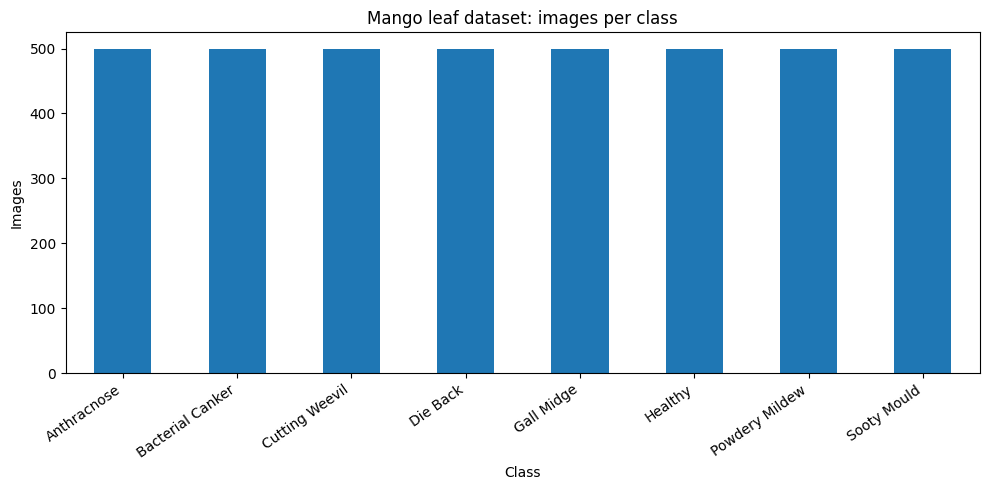

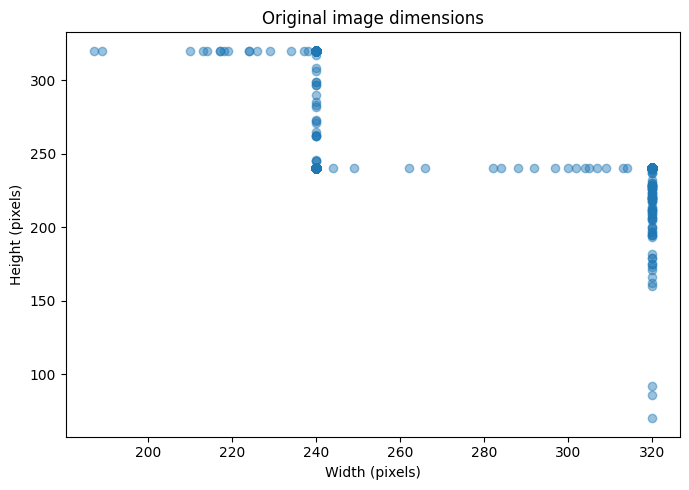

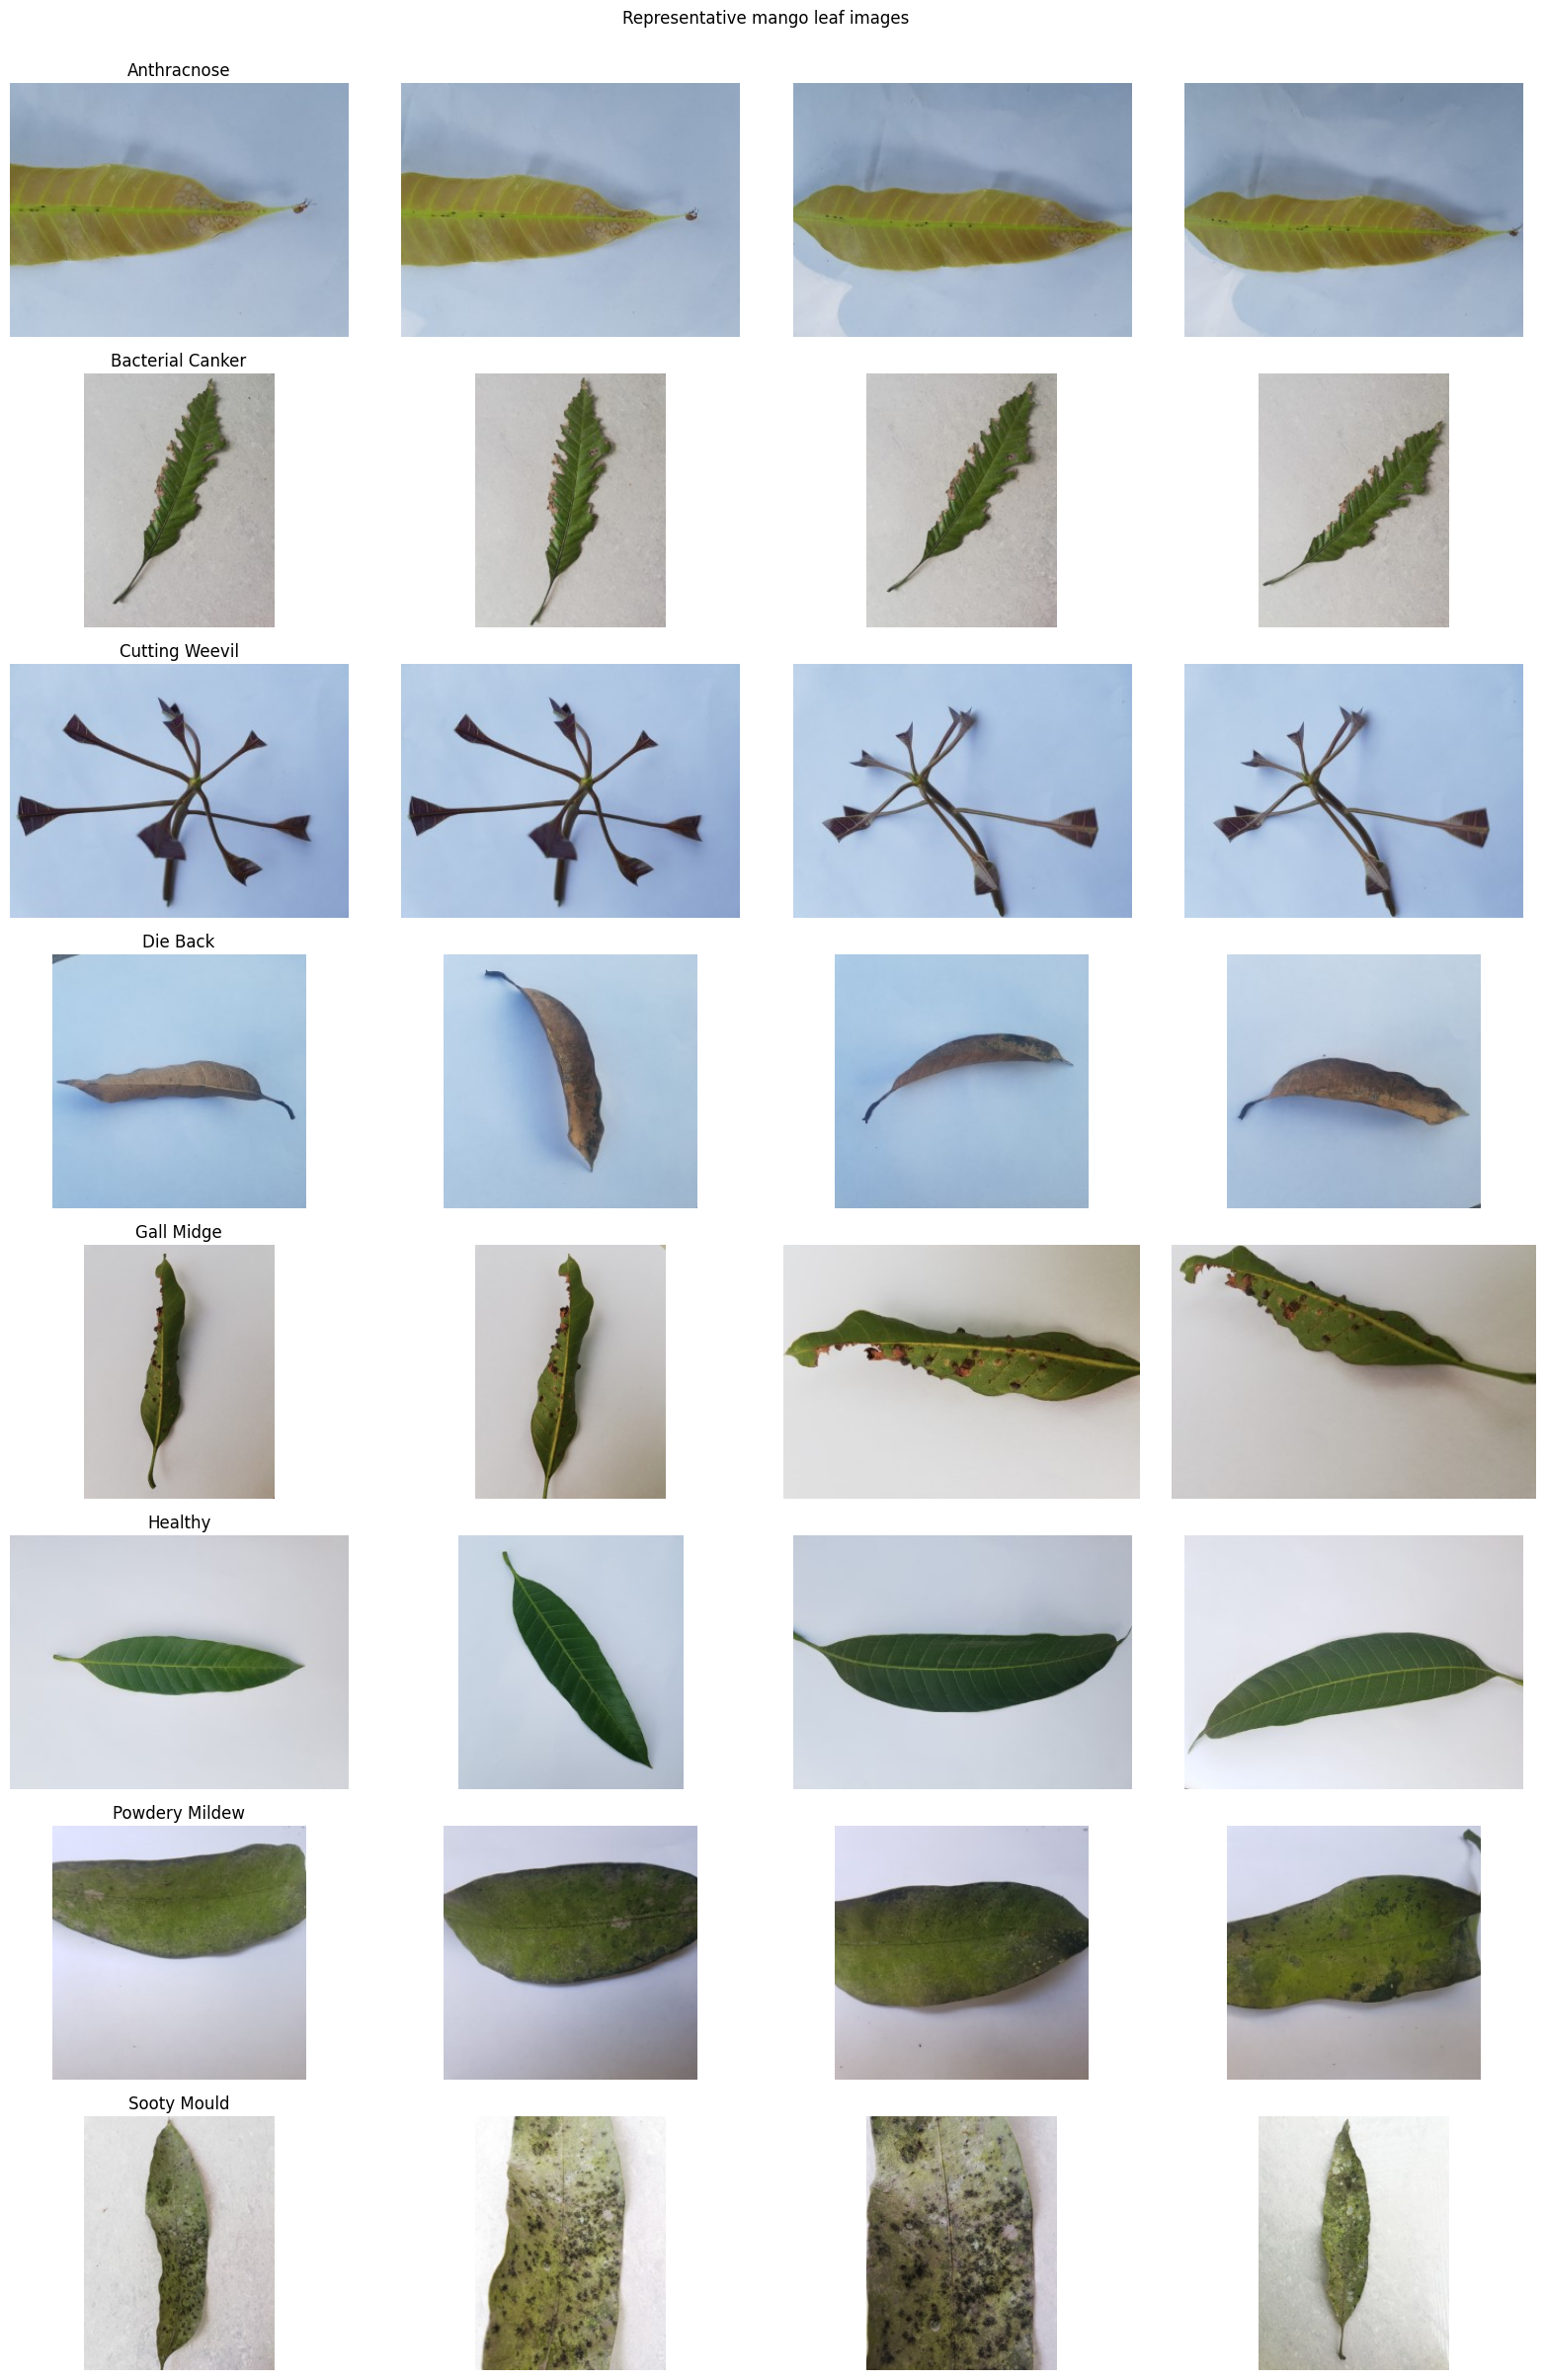

,audit,result
0,Readable images,4000
1,Classes detected,8
2,Exact duplicate hash groups,21
3,Duplicate images beyond first copy,21


In [ ]:
# Class distribution
counts = df.label.value_counts().reindex(classes)
plt.figure(figsize=(10,5)); counts.plot(kind="bar")
plt.title("Mango leaf dataset: images per class"); plt.xlabel("Class"); plt.ylabel("Images")
plt.xticks(rotation=35, ha="right"); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"fig01_class_distribution.png"), dpi=300); plt.show()

# Resolution distribution
plt.figure(figsize=(7,5))
plt.scatter(df.width, df.height, alpha=.45)
plt.title("Original image dimensions"); plt.xlabel("Width (pixels)"); plt.ylabel("Height (pixels)")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig02_resolution_scatter.png"), dpi=300); plt.show()

# Representative examples
ncols = min(4, len(classes)); fig, axes = plt.subplots(len(classes), ncols, figsize=(4*ncols, 3*len(classes)))
axes = np.array(axes).reshape(len(classes), ncols)
for i,c in enumerate(classes):
    paths = df[df.label==c].path.head(ncols).tolist()
    for j,ax in enumerate(axes[i]):
        ax.axis("off")
        if j < len(paths):
            ax.imshow(Image.open(paths[j]).convert("RGB")); ax.set_title(c if j==0 else "")
plt.suptitle("Representative mango leaf images", y=1.002)
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig03_sample_images.png"), dpi=300, bbox_inches="tight"); plt.show()

# Exact duplicate audit based on SHA-256
hash_rows=[]
for row in df.itertuples():
    h=hashlib.sha256()
    with open(row.path,"rb") as f:
        for chunk in iter(lambda:f.read(1<<20), b""): h.update(chunk)
    hash_rows.append(h.hexdigest())
df["sha256"] = hash_rows
dup_counts = df.groupby("sha256").size()
duplicate_groups = int((dup_counts>1).sum())
duplicate_images_beyond_first = int((dup_counts[dup_counts>1]-1).sum())
integrity = pd.DataFrame([
 {"audit":"Readable images","result":len(df)},
 {"audit":"Classes detected","result":len(classes)},
 {"audit":"Exact duplicate hash groups","result":duplicate_groups},
 {"audit":"Duplicate images beyond first copy","result":duplicate_images_beyond_first},
])
display(integrity)
integrity.to_csv(os.path.join(OUT_DIR,"table01_integrity_audit.csv"),index=False)
df.drop(columns=["sha256"]).to_csv(os.path.join(OUT_DIR,"dataset_manifest.csv"),index=False)

## 4. Leakage-aware train/validation/test split
A stratified 70:15:15 image-level split is used for a reproducible baseline. If exact duplicates exist, all copies are assigned to the same partition using a hash-grouped split. This still does **not** guarantee leaf-level independence when the dataset contains multiple photographs/augmentations of the same leaf without metadata. Report this limitation in the manuscript and do not describe the split as leaf-independent unless that is verified.

In [ ]:
from sklearn.model_selection import train_test_split
# If exact duplicates exist, split by SHA group. Otherwise stratify individual images.
df["group_id"] = df["sha256"]
if duplicate_groups > 0:
    group_table = df.groupby("group_id").agg(label=("label","first"), n=("path","size")).reset_index()
    train_g, temp_g = train_test_split(group_table, test_size=0.30, random_state=SEED, stratify=group_table.label)
    val_g, test_g = train_test_split(temp_g, test_size=0.50, random_state=SEED, stratify=temp_g.label)
    train_df = df[df.group_id.isin(train_g.group_id)].copy()
    val_df = df[df.group_id.isin(val_g.group_id)].copy()
    test_df = df[df.group_id.isin(test_g.group_id)].copy()
else:
    train_df, temp_df = train_test_split(df, test_size=0.30, random_state=SEED, stratify=df.label)
    val_df, test_df = train_test_split(temp_df, test_size=0.50, random_state=SEED, stratify=temp_df.label)
split_df = pd.concat([train_df.assign(split="train"),val_df.assign(split="validation"),test_df.assign(split="test")])
split_summary = split_df.groupby(["split","label"]).size().unstack(fill_value=0).reindex(columns=classes)
display(split_summary)
split_summary.to_csv(os.path.join(OUT_DIR,"table02_split_distribution.csv"))
assert set(train_df.group_id).isdisjoint(set(val_df.group_id))
assert set(train_df.group_id).isdisjoint(set(test_df.group_id))
assert set(val_df.group_id).isdisjoint(set(test_df.group_id))
print("Split sizes:", len(train_df), len(val_df), len(test_df))

label,Anthracnose,Bacterial Canker,Cutting Weevil,Die Back,Gall Midge,Healthy,Powdery Mildew,Sooty Mould
split,,,,,,,,
test,78,75,75,75,75,75,75,75
train,348,350,350,351,350,350,350,350
validation,74,75,75,74,75,75,75,75


Split sizes: 2799 598 603


## 5. TensorFlow input pipeline and TinyMangoNet
The proposed model follows the source manuscript's deployment-oriented design: depthwise-separable convolution blocks, batch normalization, ReLU, global average pooling, dropout and softmax. Input is resized to 112×112 RGB and normalized to [0,1].

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
print("TensorFlow:", tf.__version__)
AUTOTUNE = tf.data.AUTOTUNE
NUM_CLASSES = len(classes)

def load_image(path, label_id):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None,None,3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)/255.0
    return img, tf.one_hot(label_id, NUM_CLASSES)

def make_ds(frame, training=False, augment=False):
    ds = tf.data.Dataset.from_tensor_slices((frame.path.values, frame.label_id.values))
    if training: ds = ds.shuffle(min(len(frame),5000), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    if training and augment:
        aug = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomRotation(0.05),
            layers.RandomZoom(0.08),
            layers.RandomContrast(0.10)
        ])
        ds = ds.map(lambda x,y:(aug(x,training=True),y), num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_ds(train_df, training=True, augment=True)
train_eval_ds = make_ds(train_df, training=False)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)

def dsconv_block(x, filters, stride=1):
    x = layers.DepthwiseConv2D(3, strides=stride, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 1, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x); x = layers.ReLU()(x)
    return x

def build_tinymangonet(input_shape=(*IMG_SIZE,3), num_classes=NUM_CLASSES, width=1.0, use_depthwise=True, use_bn=True):
    inp = keras.Input(shape=input_shape)
    f = lambda n: max(8, int(n*width))
    x = layers.Conv2D(f(16),3,strides=2,padding="same",use_bias=not use_bn)(inp)
    if use_bn: x=layers.BatchNormalization()(x)
    x=layers.ReLU()(x)
    specs=[(32,1),(64,2),(64,1),(128,2),(128,1),(256,2)]
    for filters,stride in specs:
        filters=f(filters)
        if use_depthwise:
            x=dsconv_block(x,filters,stride)
        else:
            x=layers.Conv2D(filters,3,strides=stride,padding="same",use_bias=not use_bn)(x)
            if use_bn: x=layers.BatchNormalization()(x)
            x=layers.ReLU()(x)
    x=layers.GlobalAveragePooling2D()(x)
    x=layers.Dropout(0.30)(x)
    out=layers.Dense(num_classes,activation="softmax")(x)
    return keras.Model(inp,out,name="TinyMangoNet")

model = build_tinymangonet()
model.summary()

TensorFlow: 2.21.0


Model: "TinyMangoNet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 56, 56, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 56, 56, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 56, 56, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d                │ (None, 56, 56, 16)     │           144 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 56, 56, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 56, 56, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 56, 56, 32)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 56, 56, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_1              │ (None, 28, 28, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_2              │ (None, 28, 28, 64)     │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 28, 28, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 64)     │         4,096 │
├─────────────────────────────────┼────────────────────────┼─────────────

 Total params: 74,856 (292.41 KB)

 Trainable params: 72,616 (283.66 KB)

 Non-trainable params: 2,240 (8.75 KB)

## 6. Train a representative model and save learning curves
Class weights are calculated from the training partition only. The validation set is used for early stopping and learning-rate scheduling; the test set is reserved for final evaluation.

Epoch 1/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 33s 217ms/step - accuracy: 0.5273 - loss: 1.3618 - val_accuracy: 0.1254 - val_loss: 2.1865 - learning_rate: 5.0000e-04
Epoch 2/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 202ms/step - accuracy: 0.8156 - loss: 0.6146 - val_accuracy: 0.1237 - val_loss: 2.4856 - learning_rate: 5.0000e-04
Epoch 3/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 212ms/step - accuracy: 0.8992 - loss: 0.3678 - val_accuracy: 0.1237 - val_loss: 3.0666 - learning_rate: 5.0000e-04
Epoch 4/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 0s 215ms/step - accuracy: 0.9034 - loss: 0.3224
Epoch 4: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
88/88 ━━━━━━━━━━━━━━━━━━━━ 20s 223ms/step - accuracy: 0.9096 - loss: 0.3133 - val_accuracy: 0.1237 - val_loss: 4.2671 - learning_rate: 5.0000e-04
Epoch 5/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 18s 201ms/step - accuracy: 0.9210 - loss: 0.2405 - val_accuracy: 0.1237 - val_loss: 5.6336 - learning_rate: 2.5000e-04
Epoch 6/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 19s 211ms/step - accuracy:

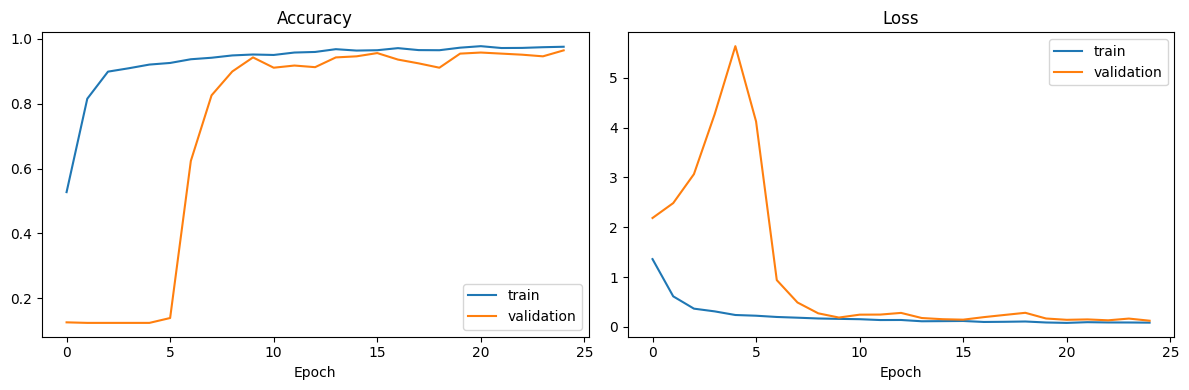

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix, matthews_corrcoef, cohen_kappa_score,
    log_loss, roc_auc_score, average_precision_score, brier_score_loss)
from sklearn.preprocessing import label_binarize

y_train = train_df.label_id.values
weights = compute_class_weight(class_weight="balanced", classes=np.arange(NUM_CLASSES), y=y_train)
class_weights = {i:float(w) for i,w in enumerate(weights)}
callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True, verbose=1),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6, verbose=1)
]
set_seed(SEED)
model = build_tinymangonet()
model.compile(optimizer=keras.optimizers.Adam(learning_rate=5e-4),
              loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS,
                    class_weight=class_weights, callbacks=callbacks, verbose=1)
model.save(os.path.join(OUT_DIR,"tinymangonet_fp32.keras"))

hist = pd.DataFrame(history.history)
hist.to_csv(os.path.join(OUT_DIR,"table03_training_history.csv"),index_label="epoch")
fig,ax=plt.subplots(1,2,figsize=(12,4))
ax[0].plot(hist["accuracy"],label="train"); ax[0].plot(hist["val_accuracy"],label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
ax[1].plot(hist["loss"],label="train"); ax[1].plot(hist["val_loss"],label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig04_learning_curves.png"),dpi=300); plt.show()

## 7. Test-set evaluation, confidence intervals and publication tables
Metrics are computed on the untouched test partition. The bootstrap interval resamples test predictions and is an uncertainty interval conditional on this test set, not a substitute for external validation.

In [ ]:
def predict_dataset(m, ds):
    probs = m.predict(ds, verbose=0)
    y_true = np.concatenate([np.argmax(y.numpy(),axis=1) for _,y in ds], axis=0)
    return y_true, probs

y_true, y_prob = predict_dataset(model, test_ds)
y_pred = y_prob.argmax(axis=1)
p_macro,r_macro,f1_macro,_ = precision_recall_fscore_support(y_true,y_pred,average="macro",zero_division=0)
p_weight,r_weight,f1_weight,_ = precision_recall_fscore_support(y_true,y_pred,average="weighted",zero_division=0)
try: auc_macro = roc_auc_score(label_binarize(y_true,classes=np.arange(NUM_CLASSES)),y_prob,average="macro",multi_class="ovr")
except Exception: auc_macro = np.nan
try: ap_macro = average_precision_score(label_binarize(y_true,classes=np.arange(NUM_CLASSES)),y_prob,average="macro")
except Exception: ap_macro = np.nan
metrics = {
 "Test images":len(y_true),
 "Accuracy":accuracy_score(y_true,y_pred),
 "Balanced accuracy":balanced_accuracy_score(y_true,y_pred),
 "Macro precision":p_macro,"Macro recall":r_macro,"Macro F1":f1_macro,
 "Weighted precision":p_weight,"Weighted recall":r_weight,"Weighted F1":f1_weight,
 "MCC":matthews_corrcoef(y_true,y_pred),"Cohen kappa":cohen_kappa_score(y_true,y_pred),
 "Macro ROC-AUC OVR":auc_macro,"Macro average precision":ap_macro,
 "Log loss":log_loss(y_true,y_prob,labels=np.arange(NUM_CLASSES))
}
metrics_df=pd.DataFrame([{"Metric":k,"Value":v} for k,v in metrics.items()])
display(metrics_df)
metrics_df.to_csv(os.path.join(OUT_DIR,"table04_overall_test_metrics.csv"),index=False)

# Bootstrap percentile CI for accuracy and macro-F1
rng=np.random.default_rng(2026); boot_acc=[]; boot_f1=[]
for _ in range(1000):
    ix=rng.integers(0,len(y_true),len(y_true))
    boot_acc.append(accuracy_score(y_true[ix],y_pred[ix]))
    boot_f1.append(precision_recall_fscore_support(y_true[ix],y_pred[ix],average="macro",zero_division=0)[2])
ci_df=pd.DataFrame([
 {"Metric":"Accuracy","Estimate":accuracy_score(y_true,y_pred),"CI95_low":np.percentile(boot_acc,2.5),"CI95_high":np.percentile(boot_acc,97.5)},
 {"Metric":"Macro F1","Estimate":f1_macro,"CI95_low":np.percentile(boot_f1,2.5),"CI95_high":np.percentile(boot_f1,97.5)}
])
display(ci_df); ci_df.to_csv(os.path.join(OUT_DIR,"table05_bootstrap_confidence_intervals.csv"),index=False)

report=classification_report(y_true,y_pred,labels=np.arange(NUM_CLASSES),target_names=classes,output_dict=True,zero_division=0)
class_metrics=pd.DataFrame(report).T
class_metrics.to_csv(os.path.join(OUT_DIR,"table06_classwise_metrics.csv"))
display(class_metrics)

,Metric,Value
0,Test images,603.000000
1,Accuracy,0.955224
2,Balanced accuracy,0.955192
3,Macro precision,0.959138
4,Macro recall,0.955192
5,Macro F1,0.954883
6,Weighted precision,0.959341
7,Weighted recall,0.955224
8,Weighted F1,0.955010
9,MCC,0.949502


,Metric,Estimate,CI95_low,CI95_high
0,Accuracy,0.955224,0.938640,0.970191
1,Macro F1,0.954883,0.937978,0.971456


,precision,recall,f1-score,support
Anthracnose,1.000000,0.961538,0.980392,78.000000
Bacterial Canker,0.974026,1.000000,0.986842,75.000000
Cutting Weevil,0.974026,1.000000,0.986842,75.000000
Die Back,0.972973,0.960000,0.966443,75.000000
Gall Midge,0.983607,0.800000,0.882353,75.000000
Healthy,0.974026,1.000000,0.986842,75.000000
Powdery Mildew,0.972222,0.933333,0.952381,75.000000
Sooty Mould,0.822222,0.986667,0.896970,75.000000
accuracy,0.955224,0.955224,0.955224,0.955224
macro avg,0.959138,0.955192,0.954883,603.000000


## 8. Confusion matrix, ROC, precision-recall and confidence analysis

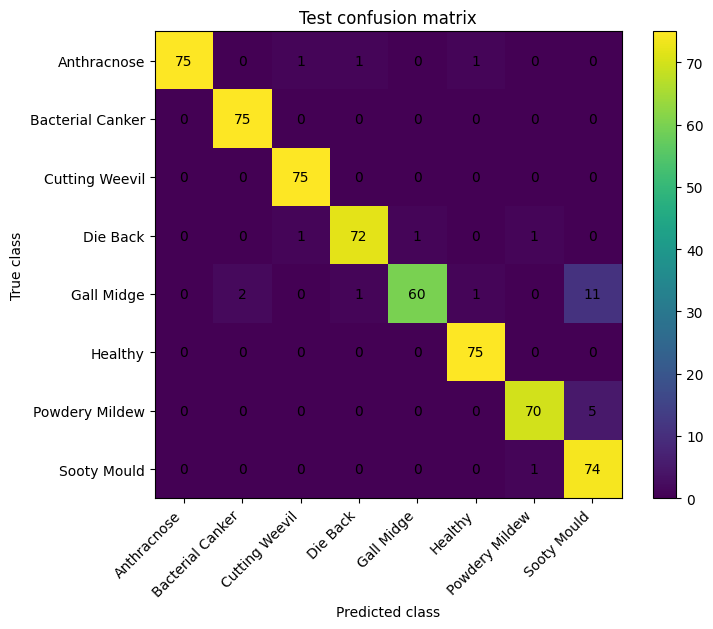

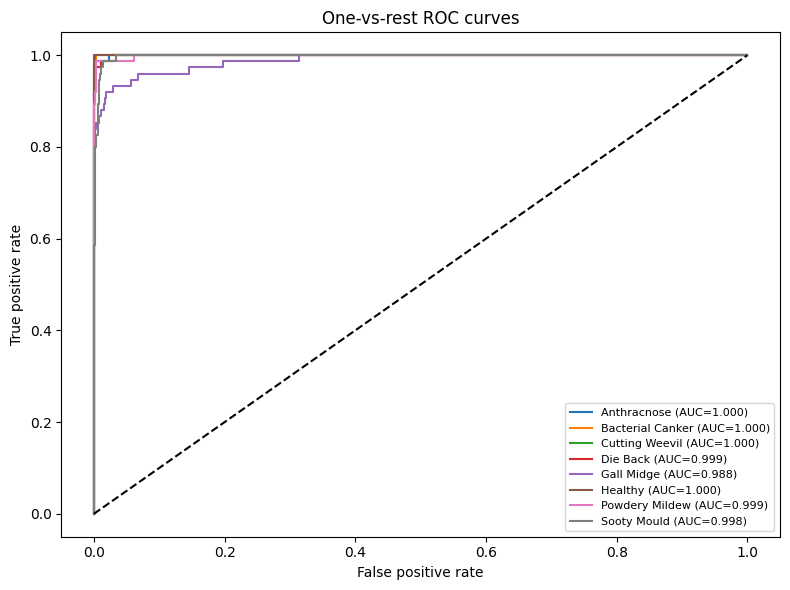

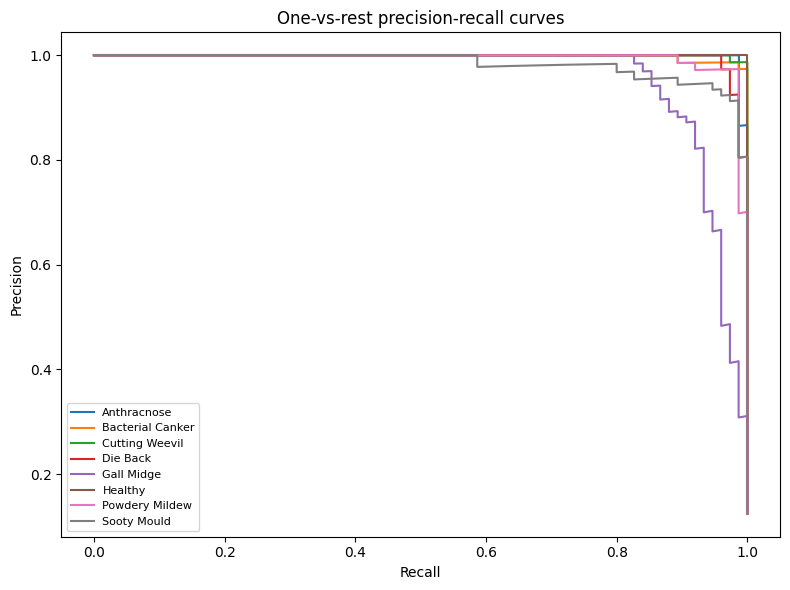

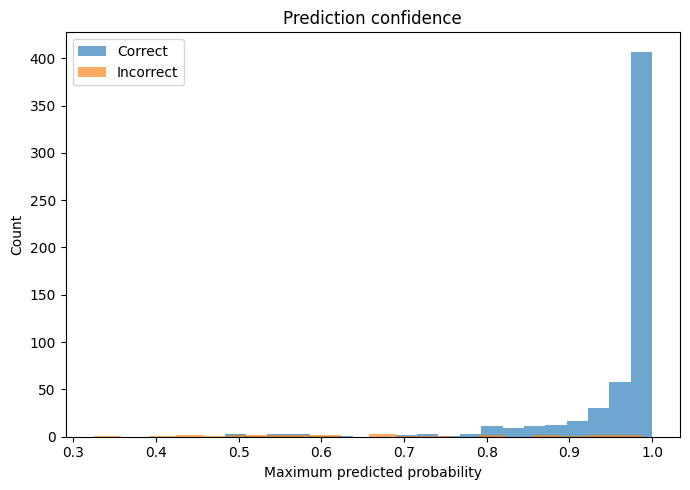

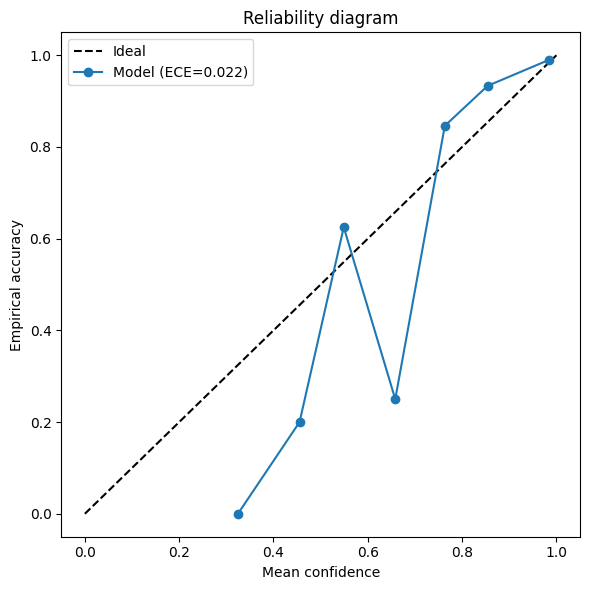

Expected calibration error (10 bins): 0.02228


In [ ]:
cm=confusion_matrix(y_true,y_pred,labels=np.arange(NUM_CLASSES))
fig,ax=plt.subplots(figsize=(max(7,NUM_CLASSES),max(6,NUM_CLASSES*.8)))
im=ax.imshow(cm,interpolation="nearest")
ax.set_title("Test confusion matrix"); ax.set_xlabel("Predicted class"); ax.set_ylabel("True class")
ax.set_xticks(range(NUM_CLASSES),classes,rotation=45,ha="right"); ax.set_yticks(range(NUM_CLASSES),classes)
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES): ax.text(j,i,str(cm[i,j]),ha="center",va="center")
fig.colorbar(im,ax=ax); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"fig05_confusion_matrix.png"),dpi=300); plt.show()
pd.DataFrame(cm,index=classes,columns=classes).to_csv(os.path.join(OUT_DIR,"table07_confusion_matrix.csv"))

from sklearn.metrics import roc_curve, precision_recall_curve
Y_bin=label_binarize(y_true,classes=np.arange(NUM_CLASSES))
plt.figure(figsize=(8,6))
for i,c in enumerate(classes):
    if len(np.unique(Y_bin[:,i]))>1:
        fpr,tpr,_=roc_curve(Y_bin[:,i],y_prob[:,i])
        plt.plot(fpr,tpr,label=f"{c} (AUC={roc_auc_score(Y_bin[:,i],y_prob[:,i]):.3f})")
plt.plot([0,1],[0,1],"k--"); plt.xlabel("False positive rate"); plt.ylabel("True positive rate")
plt.title("One-vs-rest ROC curves"); plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"fig06_roc_curves.png"),dpi=300); plt.show()

plt.figure(figsize=(8,6))
for i,c in enumerate(classes):
    if Y_bin[:,i].sum()>0:
        pr,rc,_=precision_recall_curve(Y_bin[:,i],y_prob[:,i])
        plt.plot(rc,pr,label=c)
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("One-vs-rest precision-recall curves")
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,"fig07_precision_recall.png"),dpi=300); plt.show()

confidence=y_prob.max(axis=1); correct=(y_pred==y_true)
conf_df=pd.DataFrame({"confidence":confidence,"correct":correct.astype(int),"true": [classes[i] for i in y_true],"predicted":[classes[i] for i in y_pred]})
conf_df.to_csv(os.path.join(OUT_DIR,"table08_prediction_confidence.csv"),index=False)
plt.figure(figsize=(7,5))
plt.hist(confidence[correct],bins=20,alpha=.65,label="Correct")
plt.hist(confidence[~correct],bins=20,alpha=.65,label="Incorrect")
plt.xlabel("Maximum predicted probability"); plt.ylabel("Count"); plt.title("Prediction confidence")
plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig08_confidence_distribution.png"),dpi=300); plt.show()

# Reliability diagram / expected calibration error (ECE)
def reliability_bins(y, probs, n_bins=10):
    conf=probs.max(axis=1); pred=probs.argmax(axis=1); acc=(pred==y)
    edges=np.linspace(0,1,n_bins+1); rows=[]
    for lo,hi in zip(edges[:-1],edges[1:]):
        mask=(conf>=lo)&(conf<(hi if hi<1 else hi+1e-9))
        if mask.sum(): rows.append({"bin_mid":(lo+hi)/2,"count":int(mask.sum()),"mean_confidence":float(conf[mask].mean()),"accuracy":float(acc[mask].mean())})
    return pd.DataFrame(rows)
rel=reliability_bins(y_true,y_prob)
ece=sum((r["count"]/len(y_true))*abs(r["mean_confidence"]-r["accuracy"]) for _,r in rel.iterrows())
rel.to_csv(os.path.join(OUT_DIR,"table09_calibration_bins.csv"),index=False)
plt.figure(figsize=(6,6)); plt.plot([0,1],[0,1],"k--",label="Ideal")
plt.plot(rel.mean_confidence,rel.accuracy,"o-",label=f"Model (ECE={ece:.3f})")
plt.xlabel("Mean confidence"); plt.ylabel("Empirical accuracy"); plt.title("Reliability diagram")
plt.legend(); plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig09_reliability_diagram.png"),dpi=300); plt.show()
print("Expected calibration error (10 bins):",round(ece,5))

## 9. Feature-space visualization (t-SNE)
t-SNE is run on pooled penultimate features, not on the test labels as a training signal. It is a qualitative visualization and should not be presented as a quantitative performance metric.

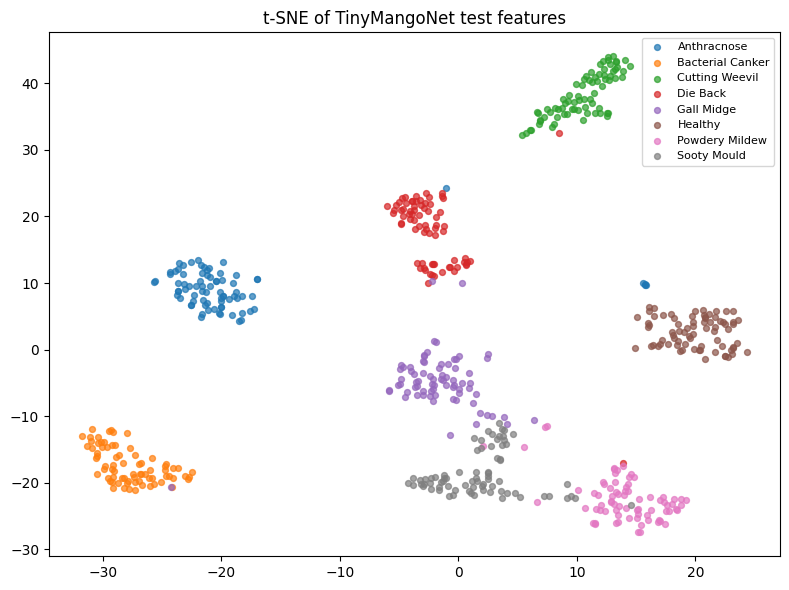

In [ ]:
feature_model=keras.Model(model.input, model.layers[-2].output)
# GlobalAveragePooling output is the second-last layer in this model.
features=feature_model.predict(test_ds,verbose=0)
from sklearn.manifold import TSNE
if len(features)>5:
    perp=min(30,max(2,(len(features)-1)//3))
    emb=TSNE(n_components=2,random_state=SEED,perplexity=perp,init="pca",learning_rate="auto").fit_transform(features)
    tsne_df=pd.DataFrame({"tSNE-1":emb[:,0],"tSNE-2":emb[:,1],"class":[classes[i] for i in y_true],"correct":correct})
    tsne_df.to_csv(os.path.join(OUT_DIR,"table10_tsne_coordinates.csv"),index=False)
    plt.figure(figsize=(8,6))
    for c in classes:
        m=tsne_df["class"]==c; plt.scatter(tsne_df.loc[m,"tSNE-1"],tsne_df.loc[m,"tSNE-2"],s=18,alpha=.7,label=c)
    plt.title("t-SNE of TinyMangoNet test features"); plt.legend(fontsize=8); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR,"fig10_tsne_features.png"),dpi=300); plt.show()

## 10. Multi-seed stability analysis
The representative model above is one run. This cell trains multiple independent seeds and reports mean, standard deviation, and individual scores. For a final journal submission, consider at least five seeds and preserve the logs.


Training seed 42

Training seed 123

Training seed 2024


,seed,epochs_run,accuracy,macro_precision,macro_recall,macro_f1,MCC
0,42,25,0.973466,0.975618,0.973333,0.973339,0.970003
1,123,24,0.965174,0.967481,0.965256,0.965181,0.960541
2,2024,25,0.960199,0.964236,0.960192,0.960264,0.955135


,Metric,mean,std
0,epochs_run,24.666667,0.577350
1,accuracy,0.966280,0.006702
2,macro_precision,0.969112,0.005864
3,macro_recall,0.966261,0.006628
4,macro_f1,0.966261,0.006604
5,MCC,0.961893,0.007526


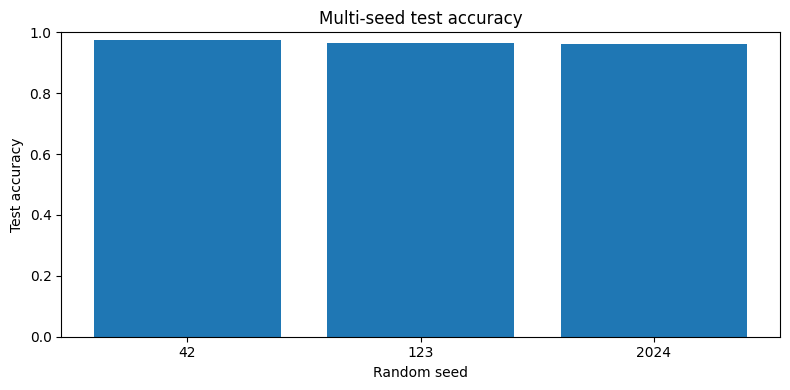

In [13]:
seed_rows=[]
for seed in RUN_SEEDS:
    print("\nTraining seed",seed)
    set_seed(seed)
    m=build_tinymangonet()
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=5e-4),loss="categorical_crossentropy",metrics=["accuracy"])
    h=m.fit(make_ds(train_df,training=True,augment=True),validation_data=val_ds,epochs=EPOCHS,
            class_weight=class_weights,
            callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=7,restore_best_weights=True),
                       keras.callbacks.ReduceLROnPlateau(monitor="val_loss",factor=.5,patience=3,min_lr=1e-6)],
            verbose=0)
    yt,yp=predict_dataset(m,test_ds); pr=yp.argmax(1)
    _,_,mf1,_=precision_recall_fscore_support(yt,pr,average="macro",zero_division=0)
    seed_rows.append({"seed":seed,"epochs_run":len(h.history["loss"]),"accuracy":accuracy_score(yt,pr),
                      "macro_precision":precision_recall_fscore_support(yt,pr,average="macro",zero_division=0)[0],
                      "macro_recall":precision_recall_fscore_support(yt,pr,average="macro",zero_division=0)[1],
                      "macro_f1":mf1,"MCC":matthews_corrcoef(yt,pr)})
    del m
    tf.keras.backend.clear_session()
seed_df=pd.DataFrame(seed_rows)
display(seed_df)
seed_df.to_csv(os.path.join(OUT_DIR,"table11_multiseed_results.csv"),index=False)
summary=seed_df.drop(columns="seed").agg(["mean","std"]).T.reset_index().rename(columns={"index":"Metric"})
display(summary); summary.to_csv(os.path.join(OUT_DIR,"table12_multiseed_summary.csv"),index=False)
plt.figure(figsize=(8,4)); plt.bar(seed_df.seed.astype(str),seed_df.accuracy)
plt.ylim(0,1); plt.xlabel("Random seed"); plt.ylabel("Test accuracy"); plt.title("Multi-seed test accuracy")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR,"fig11_multiseed_accuracy.png"),dpi=300); plt.show()
# Restore representative model from disk for subsequent cells
model=keras.models.load_model(os.path.join(OUT_DIR,"tinymangonet_fp32.keras"))

## 11. Lightweight baseline comparison
All models use the same train/validation/test partitions. Baselines use ImageNet-pretrained feature extractors and a new classification head; this is a practical comparison, not a claim that all architectures received identical compute or tuning budgets. Results are measured locally in this run.

Baseline: MobileNetV2
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Baseline: MobileNetV3Small
4334752/4334752 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Baseline: EfficientNetB0
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


,Model,Parameters,Epochs,Accuracy,Balanced accuracy,Macro precision,Macro recall,Macro F1,MCC
0,MobileNetV2,2268232,15,0.988391,0.988526,0.988603,0.988526,0.988430,0.986773
1,MobileNetV3Small,943736,15,0.975124,0.975000,0.975778,0.975000,0.974953,0.971692
2,EfficientNetB0,4059819,15,0.980100,0.980000,0.980351,0.980000,0.979897,0.977333
3,TinyMangoNet,74856,25,0.955224,0.955192,0.959138,0.955192,0.954883,0.949502


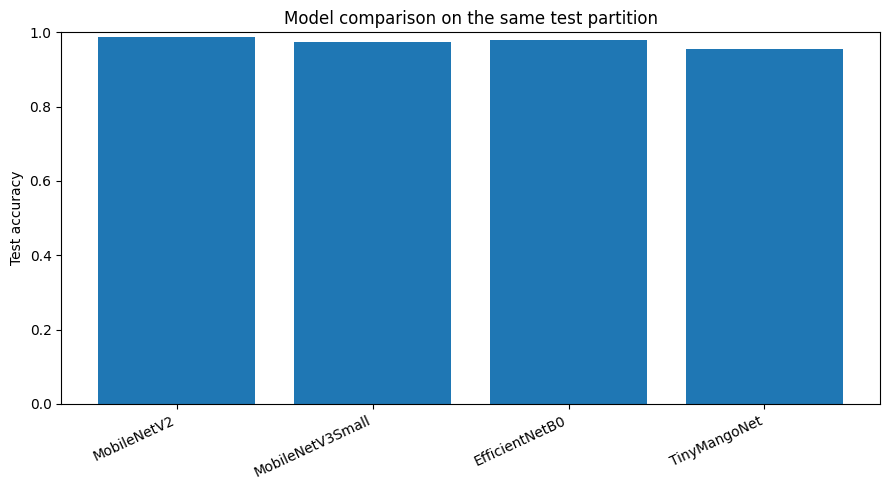

In [14]:
baseline_rows=[]
if RUN_BASELINES:
    backbone_specs=[
        ("MobileNetV2", keras.applications.MobileNetV2),
        ("MobileNetV3Small", keras.applications.MobileNetV3Small),
        ("EfficientNetB0", keras.applications.EfficientNetB0)
    ]
    def make_backbone_ds(frame, training=False):
        # Shared preprocessing outputs [0,1]; application-specific preprocessing is included in model.
        return make_ds(frame,training=training,augment=training)
    for name, ctor in backbone_specs:
        print("Baseline:",name)
        try:
            base=ctor(include_top=False,weights="imagenet",input_shape=(*IMG_SIZE,3),pooling="avg")
            base.trainable=False
            inp=keras.Input(shape=(*IMG_SIZE,3))
            x=layers.Lambda(lambda z:z*255.0)(inp)
            # EfficientNet includes rescaling internally; keep inputs [0,255]. MobileNet families need their preprocess.
            if name in ("EfficientNetB0","MobileNetV3Small"):
                # These Keras application variants include their own input rescaling/preprocessing.
                x=base(x,training=False)
            else:
                x=layers.Lambda(lambda z:keras.applications.mobilenet_v2.preprocess_input(z))(x)
                x=base(x,training=False)
            x=layers.Dropout(.25)(x); out=layers.Dense(NUM_CLASSES,activation="softmax")(x)
            bm=keras.Model(inp,out,name=name)
            bm.compile(optimizer=keras.optimizers.Adam(1e-3),loss="categorical_crossentropy",metrics=["accuracy"])
            bh=bm.fit(train_ds,validation_data=val_ds,epochs=min(EPOCHS,15),class_weight=class_weights,
                      callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=4,restore_best_weights=True)],verbose=0)
            yt,bp=predict_dataset(bm,test_ds); bpred=bp.argmax(1)
            bprec,brec,bf1,_=precision_recall_fscore_support(yt,bpred,average="macro",zero_division=0)
            baseline_rows.append({"Model":name,"Parameters":bm.count_params(),"Epochs":len(bh.history["loss"]),
                                  "Accuracy":accuracy_score(yt,bpred),"Balanced accuracy":balanced_accuracy_score(yt,bpred),
                                  "Macro precision":bprec,"Macro recall":brec,"Macro F1":bf1,"MCC":matthews_corrcoef(yt,bpred)})
            bm.save(os.path.join(OUT_DIR,f"{name.lower()}_baseline.keras"))
            del bm,base
            tf.keras.backend.clear_session()
        except Exception as e:
            print("Baseline failed; logged rather than silently omitted:",name,repr(e))
            baseline_rows.append({"Model":name,"Error":repr(e)})
    baseline_rows.append({"Model":"TinyMangoNet","Parameters":model.count_params(),"Epochs":len(history.history["loss"]),
                          "Accuracy":accuracy_score(y_true,y_pred),"Balanced accuracy":balanced_accuracy_score(y_true,y_pred),
                          "Macro precision":p_macro,"Macro recall":r_macro,"Macro F1":f1_macro,"MCC":matthews_corrcoef(y_true,y_pred)})
    baseline_df=pd.DataFrame(baseline_rows)
    display(baseline_df)
    baseline_df.to_csv(os.path.join(OUT_DIR,"table13_baseline_comparison.csv"),index=False)
    if "Accuracy" in baseline_df:
        q=baseline_df.dropna(subset=["Accuracy"])
        plt.figure(figsize=(9,5)); plt.bar(q.Model,q.Accuracy)
        plt.ylim(0,1); plt.ylabel("Test accuracy"); plt.title("Model comparison on the same test partition")
        plt.xticks(rotation=25,ha="right"); plt.tight_layout()
        plt.savefig(os.path.join(OUT_DIR,"fig12_model_comparison.png"),dpi=300); plt.show()

## 12. Ablation study
The ablation compares the full depthwise-separable network with (i) standard convolutions and (ii) reduced width. Each variant is independently trained; results are computed rather than assumed. For a more rigorous study, repeat each ablation across multiple seeds.

,Variant,Parameters,Epochs,Accuracy,Macro F1,MCC
0,TinyMangoNet_full,74856,6,0.124378,0.027655,0.000000
1,StandardConv,581240,13,0.873964,0.873164,0.860717
2,Width_0.5,21432,15,0.930348,0.929025,0.921072
3,Width_0.25,6928,15,0.794362,0.784007,0.769374


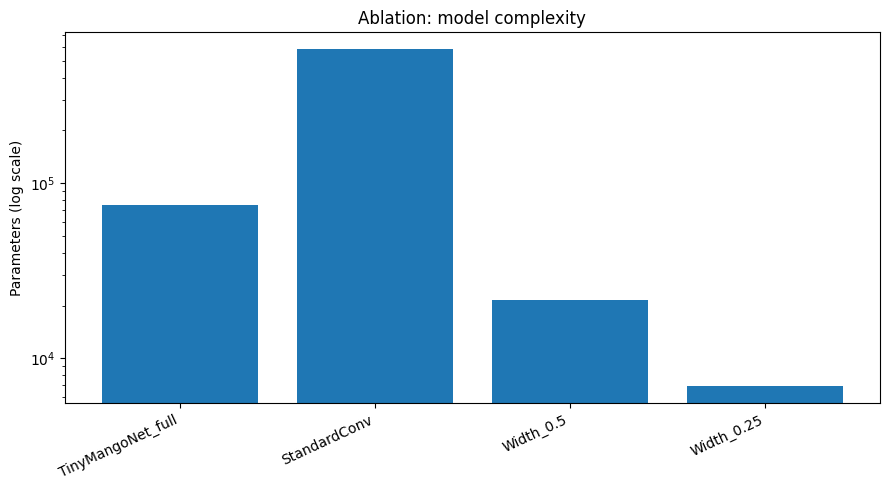

In [15]:
ablation_rows=[]
if RUN_ABLATIONS:
    ablation_specs=[
        ("TinyMangoNet_full",dict(width=1.0,use_depthwise=True,use_bn=True)),
        ("StandardConv",dict(width=1.0,use_depthwise=False,use_bn=True)),
        ("Width_0.5",dict(width=.5,use_depthwise=True,use_bn=True)),
        ("Width_0.25",dict(width=.25,use_depthwise=True,use_bn=True)),
    ]
    for nm,kwargs in ablation_specs:
        set_seed(SEED)
        am=build_tinymangonet(**kwargs)
        am.compile(optimizer=keras.optimizers.Adam(5e-4),loss="categorical_crossentropy",metrics=["accuracy"])
        ah=am.fit(train_ds,validation_data=val_ds,epochs=min(EPOCHS,15),class_weight=class_weights,
                  callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True)],verbose=0)
        yt,ap=predict_dataset(am,test_ds); aa=ap.argmax(1)
        ablation_rows.append({"Variant":nm,"Parameters":am.count_params(),"Epochs":len(ah.history["loss"]),
                              "Accuracy":accuracy_score(yt,aa),"Macro F1":precision_recall_fscore_support(yt,aa,average="macro",zero_division=0)[2],
                              "MCC":matthews_corrcoef(yt,aa)})
        am.save(os.path.join(OUT_DIR,f"ablation_{nm}.keras"))
        del am; tf.keras.backend.clear_session()
    ablation_df=pd.DataFrame(ablation_rows)
    display(ablation_df); ablation_df.to_csv(os.path.join(OUT_DIR,"table14_ablation.csv"),index=False)
    plt.figure(figsize=(9,5)); plt.bar(ablation_df.Variant,ablation_df.Parameters)
    plt.yscale("log"); plt.ylabel("Parameters (log scale)"); plt.title("Ablation: model complexity")
    plt.xticks(rotation=25,ha="right"); plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR,"fig13_ablation_parameters.png"),dpi=300); plt.show()

## 13. Model size, CPU latency proxy and INT8 quantization
The latency below is measured using the TensorFlow Lite CPU interpreter on the current Colab runtime. It is **not** microcontroller latency, energy, or a measured TFLM tensor-arena size. INT8 conversion can fail if an operator is unsupported; failures are recorded.

In [16]:
# Save FP32 model size
fp32_path=os.path.join(OUT_DIR,"tinymangonet_fp32.keras")
fp32_size=os.path.getsize(fp32_path)/1024

# TFLite FP32 and INT8 conversion
tflite_rows=[]
try:
    converter=tf.lite.TFLiteConverter.from_keras_model(model)
    tflite_fp32=converter.convert()
    fp32_tflite_path=os.path.join(OUT_DIR,"tinymangonet_fp32.tflite")
    open(fp32_tflite_path,"wb").write(tflite_fp32)
    converter=tf.lite.TFLiteConverter.from_keras_model(model)
    converter.optimizations=[tf.lite.Optimize.DEFAULT]
    def representative_data():
        for images, _ in train_ds.take(100):
            for im in images:
                yield [tf.expand_dims(im,0)]
    converter.representative_dataset=representative_data
    converter.target_spec.supported_ops=[tf.lite.OpsSet.TFLITE_BUILTINS_INT8]
    converter.inference_input_type=tf.int8
    converter.inference_output_type=tf.int8
    tflite_int8=converter.convert()
    int8_path=os.path.join(OUT_DIR,"tinymangonet_int8.tflite")
    open(int8_path,"wb").write(tflite_int8)
    for label,path in [("TFLite FP32",fp32_tflite_path),("TFLite INT8",int8_path)]:
        interpreter=tf.lite.Interpreter(model_path=path,num_threads=1)
        interpreter.allocate_tensors()
        inp=interpreter.get_input_details()[0]; out=interpreter.get_output_details()[0]
        lat=[]
        # Benchmark on a bounded set of test samples; warm-up before timing.
        sample_imgs=[]
        for images,_ in test_ds.take(2):
            sample_imgs.extend([x.numpy() for x in images])
        sample_imgs=sample_imgs[:min(50,len(sample_imgs))]
        def quantize_input(x, detail):
            if detail["dtype"]==np.int8:
                scale,zero=detail["quantization"]; return np.clip(np.round(x/scale+zero),-128,127).astype(np.int8)
            return x.astype(detail["dtype"])
        def dequantize_output(x, detail):
            if detail["dtype"]==np.int8:
                scale,zero=detail["quantization"]; return (x.astype(np.float32)-zero)*scale
            return x.astype(np.float32)
        probs=[]
        for x in sample_imgs[:min(5,len(sample_imgs))]:
            interpreter.set_tensor(inp["index"],quantize_input(x[None,...],inp)); interpreter.invoke()
        for x in sample_imgs:
            interpreter.set_tensor(inp["index"],quantize_input(x[None,...],inp))
            t0=time.perf_counter(); interpreter.invoke(); lat.append((time.perf_counter()-t0)*1000)
            probs.append(dequantize_output(interpreter.get_tensor(out["index"]),out)[0])
        # Compare proxy outputs against corresponding first test labels only when the sample ordering is aligned.
        tflite_rows.append({"Format":label,"File size KB":os.path.getsize(path)/1024,
                            "Latency mean ms":float(np.mean(lat)),"Latency median ms":float(np.median(lat)),
                            "Latency p95 ms":float(np.percentile(lat,95)),"Samples timed":len(lat)})
        if label=="TFLite INT8":
            yp_int8=np.array(probs).argmax(axis=1)
            y_test_subset=y_true[:len(yp_int8)]
            print("INT8 subset accuracy (first timed test samples):",accuracy_score(y_test_subset,yp_int8))
    display(pd.DataFrame(tflite_rows))
    pd.DataFrame(tflite_rows).to_csv(os.path.join(OUT_DIR,"table15_quantization_latency.csv"),index=False)
except Exception as e:
    print("TFLite conversion/benchmark error:",repr(e))
    pd.DataFrame([{"Error":repr(e)}]).to_csv(os.path.join(OUT_DIR,"table15_quantization_latency.csv"),index=False)

Saved artifact at '/tmp/tmpb6pvele5'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 112, 112, 3), dtype=tf.float32, name='input_layer_2')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  139140458603216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140458606288: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140458604176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140458601872: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140458607056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140433855504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140434953424: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140434955152: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140433856848: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139140433856656: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1391404349543

,Format,File size KB,Latency mean ms,Latency median ms,Latency p95 ms,Samples timed
0,TFLite FP32,291.851562,0.434395,0.423140,0.531990,50
1,TFLite INT8,113.343750,1.251766,1.188204,1.640438,50


## 14. Optional MQTT compact-message prototype
This cell demonstrates the JSON payload only. It does not publish to a public broker by default, and no physical sensor, radio, or microcontroller is assumed.

In [17]:
# Example payload using one real test prediction (no image is transmitted)
idx=0
payload={
    "device_id":"mango-node-demo",
    "timestamp_utc":pd.Timestamp.utcnow().isoformat(),
    "predicted_class":classes[int(y_pred[idx])],
    "confidence":float(np.max(y_prob[idx])),
    "model":"TinyMangoNet",
    "input_size":f"{IMG_SIZE[0]}x{IMG_SIZE[1]}",
    "note":"software demonstration; not a field diagnosis"
}
payload_json=json.dumps(payload,separators=(",",":"))
message_table=pd.DataFrame([{"Payload bytes":len(payload_json.encode("utf-8")),"JSON payload":payload_json}])
display(message_table)
message_table.to_csv(os.path.join(OUT_DIR,"table16_mqtt_message_overhead.csv"),index=False)
with open(os.path.join(OUT_DIR,"example_mqtt_payload.json"),"w") as f: json.dump(payload,f,indent=2)

,Payload bytes,JSON payload
0,246,"{""device_id"":""mango-node-demo"",""timestamp_utc""..."


## 15. Export all results
The ZIP contains tables, figures, the trained Keras model, TFLite files if conversion succeeded, the manifest, and example IoT payload. Download the ZIP at the end of this cell.

In [18]:
# Machine-readable experiment configuration
config={
 "dataset_slug":DATASET_SLUG,"image_size":IMG_SIZE,"batch_size":BATCH_SIZE,"epochs_max":EPOCHS,
 "seeds":RUN_SEEDS,"classes":classes,"class_to_idx":class_to_idx,
 "train_images":len(train_df),"validation_images":len(val_df),"test_images":len(test_df),
 "tensorflow_version":tf.__version__,"python_version":sys.version,
 "test_metrics":{k:(float(v) if isinstance(v,(np.floating,float,int,np.integer)) else str(v)) for k,v in metrics.items()},
 "caveats":["Image-level split unless exact duplicate grouping is needed; not guaranteed leaf-independent.",
            "CPU TFLite latency is a software proxy, not microcontroller latency.",
            "No field validation or energy measurement is performed by this notebook."]
}
with open(os.path.join(OUT_DIR,"experiment_config.json"),"w") as f: json.dump(config,f,indent=2)
# Export an Excel workbook with all CSV tables
csvs=[p for p in pathlib.Path(OUT_DIR).glob("*.csv")]
with pd.ExcelWriter(os.path.join(OUT_DIR,"all_results_tables.xlsx"),engine="openpyxl") as writer:
    for p in csvs:
        try:
            t=pd.read_csv(p)
            sheet=p.stem[:31]
            t.to_excel(writer,sheet_name=sheet,index=False)
        except Exception as e: print("Could not export",p,e)

zip_path="/content/TinyMangoNet_IoT_Results.zip"
with zipfile.ZipFile(zip_path,"w",zipfile.ZIP_DEFLATED) as z:
    for p in pathlib.Path(WORK_DIR).rglob("*"):
        if p.is_file() and p != pathlib.Path(zip_path):
            z.write(p,arcname=str(p.relative_to(WORK_DIR)))
print("Results ZIP:",zip_path)
print("Files generated:",len([p for p in pathlib.Path(OUT_DIR).glob("*") if p.is_file()]))
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print("Outside Colab, download the ZIP from:",zip_path)

Results ZIP: /content/TinyMangoNet_IoT_Results.zip
Files generated: 43


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
# ============================================================
# SECTION 17: GRAD-CAM EXPLAINABILITY
# TinyMangoNet-IoT: Mango Leaf Disease Classification
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

# Confirm that the trained model and test data are available
assert "model" in globals(), "Train TinyMangoNet before running Grad-CAM."
assert "test_df" in globals(), "Run the dataset split section first."
assert "classes" in globals(), "Class labels are missing."
assert "IMG_SIZE" in globals(), "IMG_SIZE is missing."
assert "OUT_DIR" in globals(), "Output directory is missing."

os.makedirs(OUT_DIR, exist_ok=True)

# Find the last convolutional layer automatically
def find_last_conv_layer_name(model):
    for layer in reversed(model.layers):
        if isinstance(
            layer,
            (layers.Conv2D, layers.DepthwiseConv2D)
        ):
            return layer.name

    raise ValueError(
        "No Conv2D or DepthwiseConv2D layer was found."
    )

LAST_CONV_NAME = find_last_conv_layer_name(model)

print("Model:", model.name)
print("Grad-CAM target layer:", LAST_CONV_NAME)
print("Input size:", IMG_SIZE)
print("Classes:", classes)

Model: TinyMangoNet
Grad-CAM target layer: conv2d_13
Input size: (112, 112)
Classes: ['Anthracnose', 'Bacterial Canker', 'Cutting Weevil', 'Die Back', 'Gall Midge', 'Healthy', 'Powdery Mildew', 'Sooty Mould']


In [20]:
# Create a model that returns:
# 1. Feature maps from the selected convolutional layer
# 2. Final class probabilities

grad_model = keras.Model(
    inputs=model.inputs,
    outputs=[
        model.get_layer(LAST_CONV_NAME).output,
        model.output
    ]
)


def compute_gradcam(image_batch, class_index=None):
    """
    image_batch: float32 tensor with shape (1, H, W, 3)
                 and pixel values normalized to [0, 1].

    class_index:
        None -> explain the predicted class
        int  -> explain a specified class
    """

    image_batch = tf.cast(image_batch, tf.float32)

    with tf.GradientTape() as tape:
        feature_maps, predictions = grad_model(
            image_batch, training=False
        )

        if class_index is None:
            class_index = int(
                tf.argmax(predictions[0]).numpy()
            )

        # Score for the target class
        target_score = predictions[:, class_index]

    # Gradient of the target score w.r.t. feature maps
    gradients = tape.gradient(
        target_score, feature_maps
    )

    if gradients is None:
        raise RuntimeError(
            "Gradients are unavailable. Check the target layer."
        )

    # Spatially average the gradients
    channel_weights = tf.reduce_mean(
        gradients, axis=(1, 2)
    )

    # Weighted combination of feature maps
    feature_maps = feature_maps[0]
    channel_weights = channel_weights[0]

    heatmap = tf.reduce_sum(
        feature_maps * channel_weights[None, None, :],
        axis=-1
    )

    # Retain positive activations and normalize
    heatmap = tf.maximum(heatmap, 0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + tf.keras.backend.epsilon()
    )

    return heatmap.numpy(), predictions.numpy()[0], class_index


print("Grad-CAM function defined successfully.")

Grad-CAM function defined successfully.


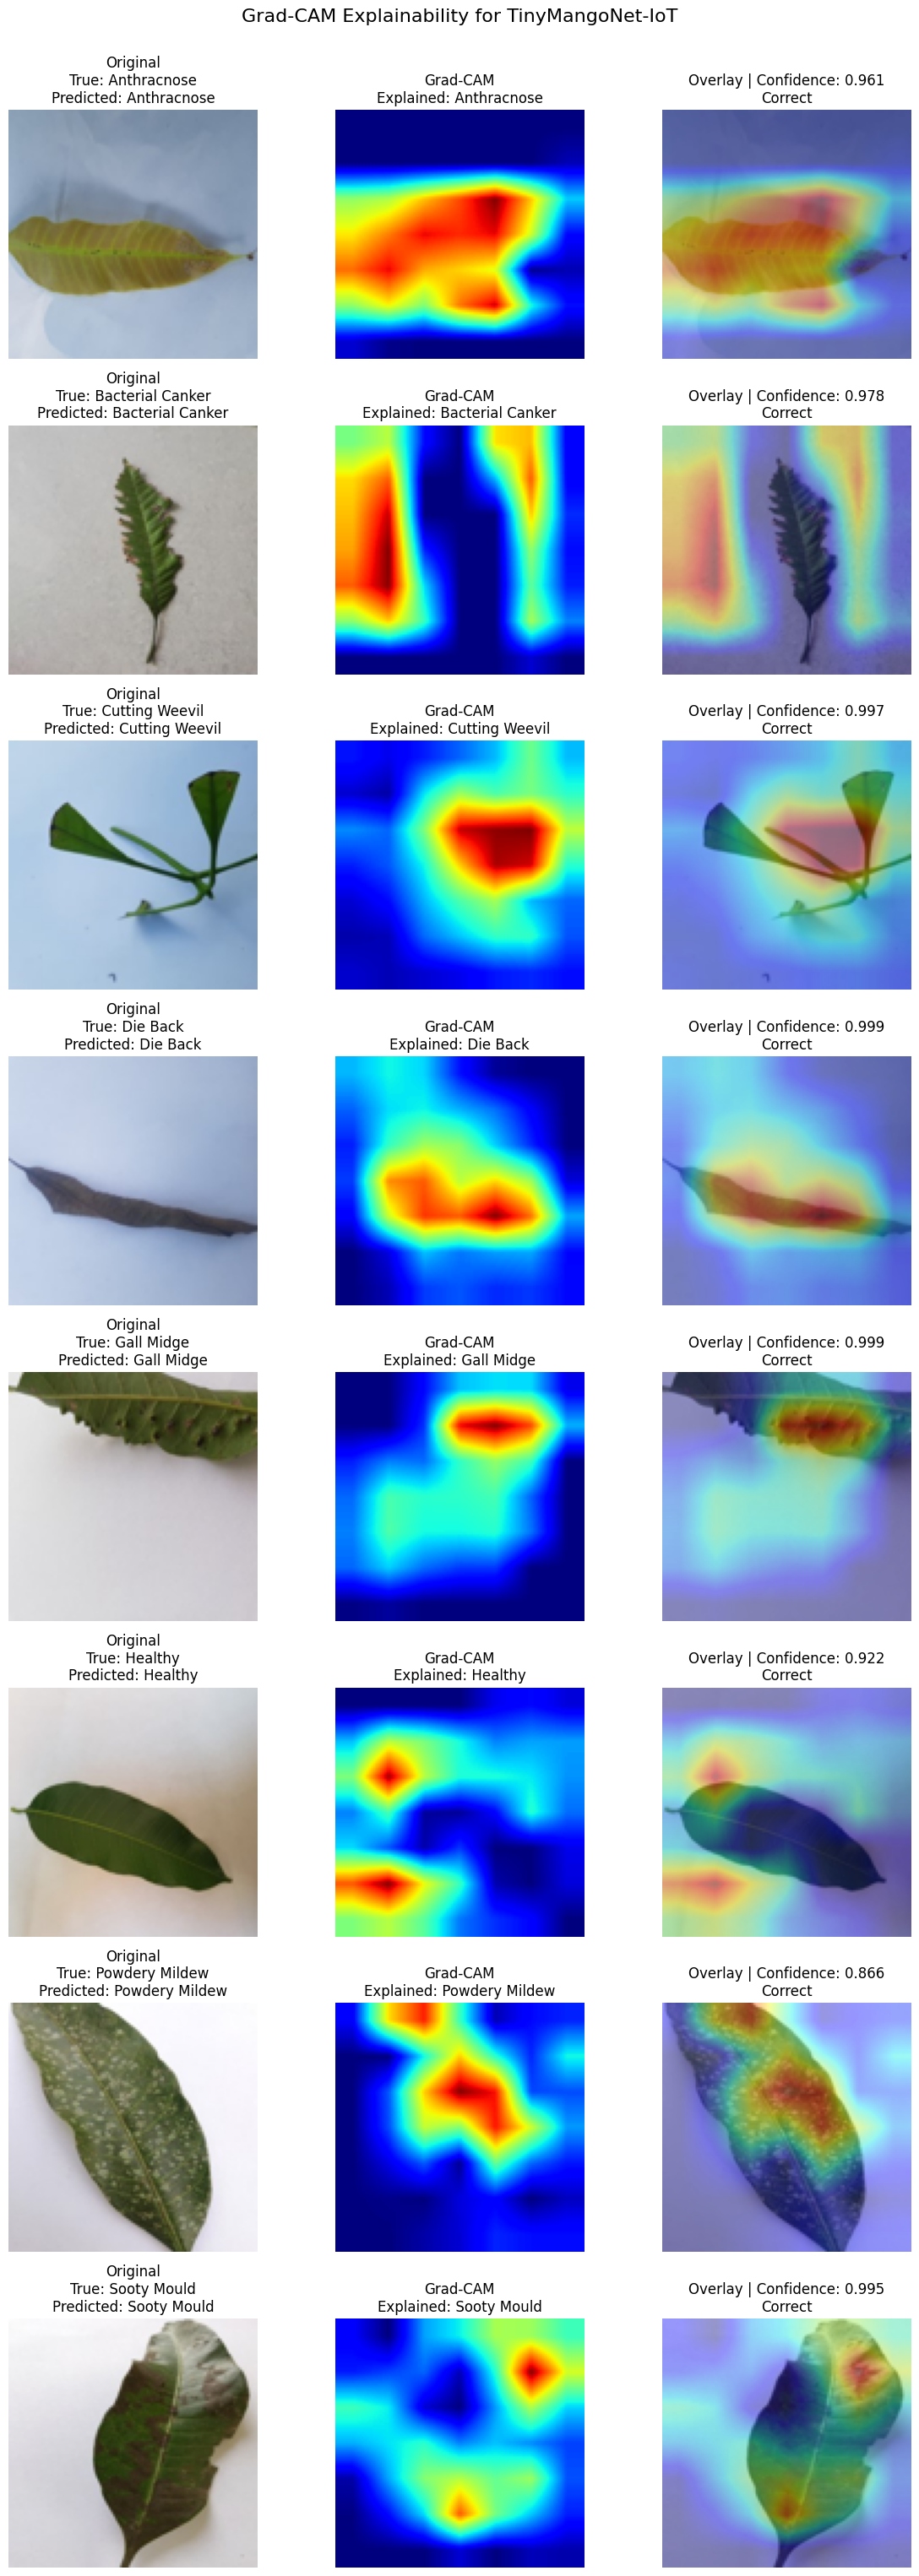

Figure saved: /content/tinymangonet_iot/outputs/fig_gradcam_mango_examples.png


In [21]:
# ============================================================
# GENERATE GRAD-CAM EXAMPLES
# ============================================================

N_EXAMPLES = min(8, len(test_df))

# Choose evenly spaced test examples instead of only
# selecting the first few rows.
selected_indices = np.linspace(
    0, len(test_df) - 1,
    N_EXAMPLES,
    dtype=int
)

gradcam_records = []

fig, axes = plt.subplots(
    N_EXAMPLES, 3,
    figsize=(12, 3.8 * N_EXAMPLES),
    squeeze=False
)

for row, idx in enumerate(selected_indices):

    record = test_df.iloc[idx]
    image_path = record["path"]
    true_id = int(record["label_id"])

    # Load image using the same preprocessing as the model
    original = Image.open(image_path).convert("RGB")
    original = original.resize(
        (IMG_SIZE[1], IMG_SIZE[0])
    )

    image_array = np.asarray(
        original, dtype=np.float32
    ) / 255.0

    image_batch = tf.convert_to_tensor(
        image_array[None, ...],
        dtype=tf.float32
    )

    # Explain the predicted class
    heatmap, probabilities, explained_class = compute_gradcam(
        image_batch
    )

    predicted_id = int(np.argmax(probabilities))
    confidence = float(probabilities[predicted_id])

    # Resize heatmap to the original model input resolution
    heatmap_resized = tf.image.resize(
        heatmap[..., None],
        IMG_SIZE,
        method="bilinear"
    ).numpy().squeeze()

    correct = predicted_id == true_id

    # Original image
    axes[row, 0].imshow(image_array)
    axes[row, 0].set_title(
        f"Original\nTrue: {classes[true_id]}\n"
        f"Predicted: {classes[predicted_id]}"
    )

    # Heatmap
    axes[row, 1].imshow(
        heatmap_resized,
        cmap="jet",
        vmin=0,
        vmax=1
    )
    axes[row, 1].set_title(
        f"Grad-CAM\nExplained: {classes[explained_class]}"
    )

    # Overlay
    axes[row, 2].imshow(image_array)
    axes[row, 2].imshow(
        heatmap_resized,
        cmap="jet",
        alpha=0.40,
        vmin=0,
        vmax=1
    )
    axes[row, 2].set_title(
        f"Overlay | Confidence: {confidence:.3f}\n"
        f"{'Correct' if correct else 'Misclassified'}"
    )

    for ax in axes[row]:
        ax.axis("off")

    gradcam_records.append({
        "Test dataframe index": int(idx),
        "Image": os.path.basename(image_path),
        "True class": classes[true_id],
        "Predicted class": classes[predicted_id],
        "Explained class": classes[explained_class],
        "Confidence": confidence,
        "Correct prediction": correct,
        "Target convolutional layer": LAST_CONV_NAME
    })

plt.suptitle(
    "Grad-CAM Explainability for TinyMangoNet-IoT",
    fontsize=16,
    y=1.002
)

plt.tight_layout()

gradcam_fig_path = os.path.join(
    OUT_DIR, "fig_gradcam_mango_examples.png"
)

plt.savefig(
    gradcam_fig_path,
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Figure saved:", gradcam_fig_path)

In [22]:
# ============================================================
# SECTION: REPEATED-RUN STATISTICAL ANALYSIS
# TinyMangoNet-IoT — Mango Leaf Disease Classification
# ============================================================

import os
import random
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    cohen_kappa_score
)

from scipy import stats

SEEDS = [42, 123, 2024, 2025, 3407]

# Use the same test set for every run.
# Do not use the test set for early stopping or model selection.

STAT_DIR = os.path.join(OUT_DIR, "repeated_run_statistics")
os.makedirs(STAT_DIR, exist_ok=True)

print("Number of independent runs:", len(SEEDS))
print("Seeds:", SEEDS)
print("Output directory:", STAT_DIR)

Number of independent runs: 5
Seeds: [42, 123, 2024, 2025, 3407]
Output directory: /content/tinymangonet_iot/outputs/repeated_run_statistics


In [30]:
# ============================================================
# FRESH MODEL TRAINING FOR EACH RANDOM SEED
# ============================================================

def train_one_run(seed, epochs=25):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

    tf.keras.backend.clear_session()

    # Replace this with your exact TinyMangoNet builder
    # if it has a different name or requires arguments.
    run_model = build_tinymangonet(
        input_shape=(IMG_SIZE[0], IMG_SIZE[1], 3),
        num_classes=len(classes)
    )

    run_model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    callbacks = [
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True
        ),
        tf.keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    ]

    history = run_model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        callbacks=callbacks,
        verbose=1
    )

    return run_model, history

In [29]:
# ============================================================
# TEST-SET METRICS (FIXED ONE-HOT SHAPE DISCREPANCY)
# ============================================================

def evaluate_repeated_run(run_model, test_ds, seed):
    # One-hot representation inside test_ds needs argmax to get the class indices
    y_true = np.concatenate([
        np.argmax(labels.numpy(), axis=1)
        for _, labels in test_ds
    ], axis=0)

    y_prob = run_model.predict(test_ds, verbose=0)
    y_pred = np.argmax(y_prob, axis=1)

    return {
        "seed": seed,
        "accuracy": accuracy_score(y_true, y_pred),
        "balanced_accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),
        "macro_precision": precision_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_recall": recall_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "macro_f1": f1_score(
            y_true, y_pred, average="macro", zero_division=0
        ),
        "weighted_f1": f1_score(
            y_true, y_pred, average="weighted", zero_division=0
        ),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "Cohen_kappa": cohen_kappa_score(y_true, y_pred)
    }

In [31]:
# ============================================================
# RUN EXPERIMENTS
# ============================================================

run_results = []
run_histories = []

for seed in SEEDS:
    print(f"\n{'='*60}")
    print(f"Starting run with seed {seed}")
    print(f"{'='*60}")

    run_model, history = train_one_run(seed, epochs=25)

    metrics = evaluate_repeated_run(
        run_model, test_ds, seed
    )

    run_results.append(metrics)
    run_histories.append({
        "seed": seed,
        "history": history.history
    })

    print(pd.Series(metrics).to_string())

    # Release resources before the next run
    del run_model
    tf.keras.backend.clear_session()

runs_df = pd.DataFrame(run_results)

runs_path = os.path.join(
    STAT_DIR, "table_repeated_run_individual_results.csv"
)

runs_df.to_csv(runs_path, index=False)

display(runs_df)
print("Saved:", runs_path)


Starting run with seed 42
Epoch 1/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 24s 210ms/step - accuracy: 0.6052 - loss: 1.1225 - val_accuracy: 0.1237 - val_loss: 2.3699 - learning_rate: 0.0010
Epoch 2/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 182ms/step - accuracy: 0.8553 - loss: 0.4625 - val_accuracy: 0.1237 - val_loss: 3.0958 - learning_rate: 0.0010
Epoch 3/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 184ms/step - accuracy: 0.9178 - loss: 0.2813 - val_accuracy: 0.1237 - val_loss: 4.5033 - learning_rate: 0.0010
Epoch 4/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 17s 186ms/step - accuracy: 0.9343 - loss: 0.2050 - val_accuracy: 0.1237 - val_loss: 6.2373 - learning_rate: 5.0000e-04
Epoch 5/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 185ms/step - accuracy: 0.9471 - loss: 0.1863 - val_accuracy: 0.1254 - val_loss: 6.6700 - learning_rate: 5.0000e-04
Epoch 6/25
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 186ms/step - accuracy: 0.9575 - loss: 0.1494 - val_accuracy: 0.2358 - val_loss: 3.7151 - learning_rate: 2.5000e-04
seed                 42.000000
accuracy    

,seed,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,MCC,Cohen_kappa
0,42,0.124378,0.125,0.015547,0.125,0.027655,0.027517,0.0,0.0
1,123,0.129353,0.125,0.016169,0.125,0.028634,0.029632,0.0,0.0
2,2024,0.129353,0.125,0.016169,0.125,0.028634,0.029632,0.0,0.0
3,2025,0.124378,0.125,0.015547,0.125,0.027655,0.027517,0.0,0.0
4,3407,0.124378,0.125,0.015547,0.125,0.027655,0.027517,0.0,0.0


Saved: /content/tinymangonet_iot/outputs/repeated_run_statistics/table_repeated_run_individual_results.csv


In [32]:
# ============================================================
# SUMMARY STATISTICS ACROSS RUNS
# ============================================================

metric_columns = [
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "MCC",
    "Cohen_kappa"
]

summary_rows = []

for metric in metric_columns:
    values = runs_df[metric].dropna().to_numpy()

    n = len(values)
    mean_value = values.mean()
    std_value = values.std(ddof=1)

    if n > 1:
        sem = stats.sem(values)
        ci_low, ci_high = stats.t.interval(
            confidence=0.95,
            df=n - 1,
            loc=mean_value,
            scale=sem
        )
    else:
        ci_low, ci_high = np.nan, np.nan

    summary_rows.append({
        "Metric": metric,
        "Mean": mean_value,
        "SD": std_value,
        "95% CI lower": ci_low,
        "95% CI upper": ci_high,
        "Mean ± SD": f"{mean_value:.4f} ± {std_value:.4f}"
    })

summary_df = pd.DataFrame(summary_rows)

summary_path = os.path.join(
    STAT_DIR, "table_repeated_run_summary.csv"
)

summary_df.to_csv(summary_path, index=False)

display(summary_df.round(4))
print("Saved:", summary_path)

,Metric,Mean,SD,95% CI lower,95% CI upper,Mean ± SD
0,accuracy,0.1264,0.0027,0.1230,0.1298,0.1264 ± 0.0027
1,balanced_accuracy,0.1250,0.0000,NaN,NaN,0.1250 ± 0.0000
2,macro_precision,0.0158,0.0003,0.0154,0.0162,0.0158 ± 0.0003
3,macro_recall,0.1250,0.0000,NaN,NaN,0.1250 ± 0.0000
4,macro_f1,0.0280,0.0005,0.0274,0.0287,0.0280 ± 0.0005
5,weighted_f1,0.0284,0.0012,0.0269,0.0298,0.0284 ± 0.0012
6,MCC,0.0000,0.0000,NaN,NaN,0.0000 ± 0.0000
7,Cohen_kappa,0.0000,0.0000,NaN,NaN,0.0000 ± 0.0000


Saved: /content/tinymangonet_iot/outputs/repeated_run_statistics/table_repeated_run_summary.csv


In [33]:
# ============================================================
# EXPORT ALL STATISTICAL TABLES
# ============================================================

excel_path = os.path.join(
    STAT_DIR, "TinyMangoNet_Repeated_Run_Analysis.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    runs_df.to_excel(
        writer, sheet_name="Individual Runs", index=False
    )
    summary_df.to_excel(
        writer, sheet_name="Mean SD CI", index=False
    )

print("Excel workbook saved:", excel_path)

Excel workbook saved: /content/tinymangonet_iot/outputs/repeated_run_statistics/TinyMangoNet_Repeated_Run_Analysis.xlsx


In [34]:
# ============================================================
# SECTION: NEAR-DUPLICATE DETECTION AND GROUP-AWARE SPLITTING
# ============================================================

!pip -q install ImageHash

import os
import hashlib
import itertools
import numpy as np
import pandas as pd
import imagehash

from PIL import Image, ImageFile
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.model_selection import GroupShuffleSplit
from collections import defaultdict

ImageFile.LOAD_TRUNCATED_IMAGES = True

PHASH_THRESHOLD = 6  # Candidate threshold; validate on sample pairs

LEAKAGE_DIR = os.path.join(OUT_DIR, "leakage_audit")
os.makedirs(LEAKAGE_DIR, exist_ok=True)

print("Near-duplicate threshold:", PHASH_THRESHOLD)
print("Output:", LEAKAGE_DIR)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 4.3 MB/s eta 0:00:00
Near-duplicate threshold: 6
Output: /content/tinymangonet_iot/outputs/leakage_audit


In [36]:
# If manifest DataFrame (stored as 'df') already exists, reuse it.
# Expected columns: path and label

assert "df" in globals(), (
    "Run the dataset-discovery cell first to create df."
)

PATH_COL = "path"
LABEL_COL = "label"

assert PATH_COL in df.columns
assert LABEL_COL in df.columns

audit_df = df[[PATH_COL, LABEL_COL]].copy()
audit_df = audit_df.dropna().reset_index(drop=True)

audit_df[PATH_COL] = audit_df[PATH_COL].astype(str)
audit_df[LABEL_COL] = audit_df[LABEL_COL].astype(str)

audit_df = audit_df[
    audit_df[PATH_COL].map(os.path.isfile)
].reset_index(drop=True)

print("Images included in audit:", len(audit_df))
print("Classes:", audit_df[LABEL_COL].nunique())

display(
    audit_df.groupby(LABEL_COL).size()
    .rename("image_count")
    .reset_index()
)

Images included in audit: 4000
Classes: 8


,label,image_count
0,Anthracnose,500
1,Bacterial Canker,500
2,Cutting Weevil,500
3,Die Back,500
4,Gall Midge,500
5,Healthy,500
6,Powdery Mildew,500
7,Sooty Mould,500


In [37]:
# ============================================================
# HASH ALL IMAGES
# ============================================================

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()


def compute_phash(path):
    try:
        with Image.open(path) as im:
            return str(imagehash.phash(im.convert("RGB")))
    except Exception as exc:
        print("Could not process:", path, "|", exc)
        return None


sha_values = []
phash_values = []

for i, path in enumerate(audit_df[PATH_COL]):
    try:
        sha_values.append(sha256_file(path))
        phash_values.append(compute_phash(path))
    except Exception as exc:
        print("Hash error:", path, exc)
        sha_values.append(None)
        phash_values.append(None)

    if (i + 1) % 500 == 0:
        print(f"Processed {i+1}/{len(audit_df)} images")

audit_df["sha256"] = sha_values
audit_df["phash"] = phash_values

audit_df.to_csv(
    os.path.join(LEAKAGE_DIR, "image_hash_manifest.csv"),
    index=False
)

print("Hashing complete.")

Processed 500/4000 images
Processed 1000/4000 images
Processed 1500/4000 images
Processed 2000/4000 images
Processed 2500/4000 images
Processed 3000/4000 images
Processed 3500/4000 images
Processed 4000/4000 images
Hashing complete.


In [38]:
# ============================================================
# EXACT DUPLICATE AUDIT
# ============================================================

valid_sha = audit_df.dropna(subset=["sha256"])

exact_groups = (
    valid_sha.groupby("sha256")
    .filter(lambda g: len(g) > 1)
    .sort_values("sha256")
)

print("Images involved in exact duplicate groups:",
      len(exact_groups))
print("Exact duplicate groups:",
      exact_groups["sha256"].nunique())

exact_groups.to_csv(
    os.path.join(LEAKAGE_DIR, "exact_duplicate_groups.csv"),
    index=False
)

display(exact_groups.head(30))

Images involved in exact duplicate groups: 42
Exact duplicate groups: 21


,path,label,sha256,phash
169,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,2565f502b7385f430982272047ef9dd30152d9fd18d24f...,f68bc5723b8d260a
168,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,2565f502b7385f430982272047ef9dd30152d9fd18d24f...,f68bc5723b8d260a
187,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,25f49df1994478873a0191091a1413ed63a698e117a2be...,e3b1cc663369cc86
186,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,25f49df1994478873a0191091a1413ed63a698e117a2be...,e3b1cc663369cc86
310,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,2c2de614abdf4eafb703fce0cb911f0895806067bac246...,836ad4963b6be894
309,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,2c2de614abdf4eafb703fce0cb911f0895806067bac246...,836ad4963b6be894
154,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,38c99c94cbbe269b5ac1ea712b77a1b7ec26878395bc9d...,e49bcce733380cc6
155,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,38c99c94cbbe269b5ac1ea712b77a1b7ec26878395bc9d...,e49bcce733380cc6
300,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,471bfbab6a067953d28ac803b6a0b13486b6768a843e24...,f996c76834936b0c
299,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,471bfbab6a067953d28ac803b6a0b13486b6768a843e24...,f996c76834936b0c


In [39]:
# ============================================================
# PERCEPTUAL HASH NEAR-DUPLICATE PAIRS
# ============================================================

valid_rows = audit_df.dropna(subset=["phash"]).reset_index(drop=True)

hash_objects = [
    imagehash.hex_to_hash(h)
    for h in valid_rows["phash"]
]

near_pairs = []

for i in range(len(valid_rows)):
    for j in range(i + 1, len(valid_rows)):
        # Exact duplicates are already recorded separately.
        if valid_rows.loc[i, "sha256"] == valid_rows.loc[j, "sha256"]:
            continue

        distance = hash_objects[i] - hash_objects[j]

        if distance <= PHASH_THRESHOLD:
            near_pairs.append({
                "image_a": valid_rows.loc[i, PATH_COL],
                "image_b": valid_rows.loc[j, PATH_COL],
                "label_a": valid_rows.loc[i, LABEL_COL],
                "label_b": valid_rows.loc[j, LABEL_COL],
                "sha256_a": valid_rows.loc[i, "sha256"],
                "sha256_b": valid_rows.loc[j, "sha256"],
                "phash_distance": distance
            })

near_df = pd.DataFrame(near_pairs)

near_path = os.path.join(
    LEAKAGE_DIR, "perceptual_near_duplicate_pairs.csv"
)
near_df.to_csv(near_path, index=False)

print("Near-duplicate pairs detected:", len(near_df))
print("Saved:", near_path)

display(near_df.head(30))

Near-duplicate pairs detected: 498
Saved: /content/tinymangonet_iot/outputs/leakage_audit/perceptual_near_duplicate_pairs.csv


,image_a,image_b,label_a,label_b,sha256_a,sha256_b,phash_distance
0,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,Anthracnose,812532ffc8745a6959256a427c06ca77020e96ae647d2d...,025f9860dbdddf2707e79d39a3c9f2f05f33b1582cec92...,2
1,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Die Back/20...,Anthracnose,Die Back,62146d6baa0440a55ffd081c47c19631592eb37cbd3c71...,558e1c6f13ef80e7aa5470c2076a0599d79f785ad47cb0...,6
2,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,Anthracnose,7d38263bfa9c58d9cad9aa3f240217ce573d29659be4d7...,efa7c88e3dd6737ffdc71df6af734bb85f163fc17f9910...,6
3,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Healthy/202...,Anthracnose,Healthy,1c81ed30edc29a9c48fa53d15e95a2c990abb5e13d597d...,213e55fc2759136be6633ab56b45922b364bcf2f5d7313...,6
4,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Die Back/20...,Anthracnose,Die Back,15c586b4402940fcc9ffd8c7d4704bcfbc865304c2b49d...,f4426e4043df4a036a9f2fa213c0a588adba9117597865...,6
5,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Die Back/20...,Anthracnose,Die Back,15c586b4402940fcc9ffd8c7d4704bcfbc865304c2b49d...,f4426e4043df4a036a9f2fa213c0a588adba9117597865...,6
6,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,Anthracnose,29092db4105b63b294d8e558c59d71c1fe640cf21a58ca...,53c8fa4447f6b6b7ce20aefd5b0bb25f46c9e8cdf9912f...,6
7,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Healthy/202...,Anthracnose,Healthy,53c8fa4447f6b6b7ce20aefd5b0bb25f46c9e8cdf9912f...,c9be8995d5c67b853a160dc85e2fa223f2e60b3c006adc...,6
8,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Anthracnose...,Anthracnose,Anthracnose,b90e3f01bd31d3cf499a48c7ae80fe29fe285b49240355...,6296284a72376c1ed0fa0e1f8628a0106f08654a75652b...,2
9,/content/kaggle_mango_leaf_disease/Anthracnose...,/content/kaggle_mango_leaf_disease/Bacterial C...,Anthracnose,Bacterial Canker,3c79dd1b350ab35874a68f4208fd09cf776cf7cb550f26...,f9601713ffbe4d301edbc1b09318f290bcde03f80f5fc9...,6


In [40]:
                                                                                                                                                                                # ============================================================
# CONNECTED COMPONENTS FOR GROUP ASSIGNMENT
# ============================================================

paths = audit_df[PATH_COL].tolist()
parent = {p: p for p in paths}


def find(x):
    while parent[x] != x:
        parent[x] = parent[parent[x]]
        x = parent[x]
    return x


def union(a, b):
    ra, rb = find(a), find(b)
    if ra != rb:
        parent[rb] = ra


# Link exact duplicates
for _, group in audit_df.dropna(subset=["sha256"]).groupby("sha256"):
    members = group[PATH_COL].tolist()
    for p in members[1:]:
        union(members[0], p)

# Link perceptual near-duplicates
for _, row in near_df.iterrows():
    union(row["image_a"], row["image_b"])

audit_df["group_id"] = [
    "group_" + hashlib.sha1(
        find(p).encode("utf-8")
    ).hexdigest()[:12]
    for p in audit_df[PATH_COL]
]

group_summary = (
    audit_df.groupby("group_id")
    .agg(
        image_count=(PATH_COL, "size"),
        class_count=(LABEL_COL, "nunique"),
        labels=(LABEL_COL, lambda x: ", ".join(sorted(set(x))))
    )
    .reset_index()
    .sort_values("image_count", ascending=False)
)

group_summary.to_csv(
    os.path.join(LEAKAGE_DIR, "image_group_summary.csv"),
    index=False
)

print("Total images:", len(audit_df))
print("Total groups:", audit_df["group_id"].nunique())
print("Groups containing multiple classes:",
      int((group_summary["class_count"] > 1).sum()))

display(group_summary.head(20))

Total images: 4000
Total groups: 3526
Groups containing multiple classes: 45


,group_id,image_count,class_count,labels
911,group_44ffd2570ef8,6,2,"Anthracnose, Die Back"
43,group_03a500933656,6,2,"Anthracnose, Die Back"
593,group_2c9a7d95fe30,6,2,"Die Back, Healthy"
119,group_098ff312050e,5,3,"Gall Midge, Powdery Mildew, Sooty Mould"
365,group_1b8f5f6fe59e,5,3,"Die Back, Gall Midge, Healthy"
2127,group_9e7b39386f44,5,4,"Die Back, Gall Midge, Healthy, Sooty Mould"
23,group_020e05b343c3,5,1,Healthy
2284,group_a9e2925ae9ed,4,1,Cutting Weevil
3096,group_e336b81d0fa5,4,1,Healthy
985,group_4a17cccf17b0,4,1,Cutting Weevil


In [41]:
# ============================================================
# GROUP-AWARE TRAIN / VALIDATION / TEST SPLIT
# ============================================================

# First split: 70% train, 30% remaining
split1 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, remaining_idx = next(
    split1.split(
        audit_df,
        groups=audit_df["group_id"]
    )
)

train_df = audit_df.iloc[train_idx].copy()
remaining_df = audit_df.iloc[remaining_idx].copy()

# Split remaining 30% into approximately 15% validation
# and 15% test. Half of the remaining data goes to test.
split2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=123
)

val_rel_idx, test_rel_idx = next(
    split2.split(
        remaining_df,
        groups=remaining_df["group_id"]
    )
)

val_df = remaining_df.iloc[val_rel_idx].copy()
test_df = remaining_df.iloc[test_rel_idx].copy()

train_df["split"] = "train"
val_df["split"] = "validation"
test_df["split"] = "test"

split_df = pd.concat(
    [train_df, val_df, test_df],
    ignore_index=True
)

# Verify that no group crosses split boundaries
split_group_counts = split_df.groupby("group_id")["split"].nunique()
assert split_group_counts.max() == 1, (
    "Leakage detected: a group appears in multiple splits."
)

split_df.to_csv(
    os.path.join(LEAKAGE_DIR, "group_aware_split_manifest.csv"),
    index=False
)

for name, df in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    print(
        f"{name}: {len(df)} images "
        f"({100*len(df)/len(split_df):.2f}%), "
        f"{df['group_id'].nunique()} groups"
    )

print("\nClass distribution by split:")
display(pd.crosstab(split_df["split"], split_df[LABEL_COL]))

Train: 2801 images (70.03%), 2468 groups
Validation: 608 images (15.20%), 529 groups
Test: 591 images (14.78%), 529 groups

Class distribution by split:


label,Anthracnose,Bacterial Canker,Cutting Weevil,Die Back,Gall Midge,Healthy,Powdery Mildew,Sooty Mould
split,,,,,,,,
test,79,83,72,83,68,71,69,66
train,341,352,340,339,367,339,361,362
validation,80,65,88,78,65,90,70,72


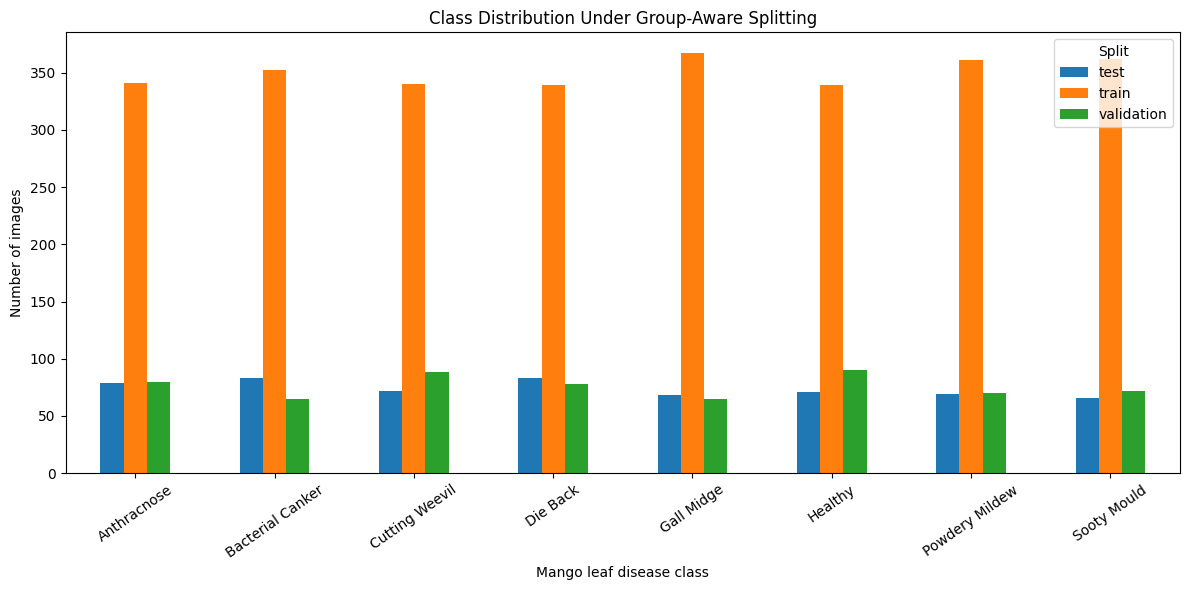

Saved: /content/tinymangonet_iot/outputs/leakage_audit/fig_group_aware_class_distribution.png


In [42]:
# ============================================================
# FIGURE: CLASS DISTRIBUTION AFTER GROUP-AWARE SPLITTING
# ============================================================

distribution = pd.crosstab(
    split_df[LABEL_COL],
    split_df["split"]
)

ax = distribution.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Class Distribution Under Group-Aware Splitting")
ax.set_xlabel("Mango leaf disease class")
ax.set_ylabel("Number of images")
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Split")
plt.tight_layout()

split_fig = os.path.join(
    LEAKAGE_DIR, "fig_group_aware_class_distribution.png"
)

plt.savefig(split_fig, dpi=300, bbox_inches="tight")
plt.show()

print("Saved:", split_fig)

## 16. Manuscript reporting checklist
Before writing the final Results section:
- Use the actual class names and counts printed by the notebook.
- Report the split protocol, seed list, image dimensions, augmentation, optimizer and stopping rule.
- Report mean ± standard deviation across independent seeds; keep the representative-run confusion matrix clearly labeled.
- Report class-wise precision, recall, F1, macro/weighted averages, MCC, ROC-AUC/PR-AUC where defined, and confidence intervals.
- Describe TFLite CPU timing as a **software proxy** only. Do not claim microcontroller deployment, measured energy, or tensor-arena usage without physical TFLM experiments.
- Discuss the controlled-background / dataset-domain limitation and obtain independent orchard images for external validation if possible.
- Verify dataset license and cite the dataset's original publication and Kaggle distribution.
- Do not copy performance values from the grape manuscript; all mango results must come from this run.